# Лабораторная работа 5. Прогноз площади лесного пожара

Цель — по сведениям на момент обнаружения оценить итоговую площадь пожара в акрах.
Источник: предоставленный `lab_5.csv`, 2019–2024 годы. Единица наблюдения — одно возгорание.

Ноутбук содержит выполненные расчёты, графики, объяснения и комментарии к коду.
Для повторного запуска положите `lab_5.csv` рядом с ноутбуком и выполните **Restart Kernel → Run All**.
В Google Colab CSV можно загрузить при запуске ячейки чтения. Нужны Python 3,
numpy, pandas, matplotlib и scikit-learn ≥ 1.2. Новые данные можно использовать, изменив `DATA_PATH` для предсказания.

Итоговая площадь зависит и от будущей погоды, и от тушения. В этой таблице мы прогнозируем
наблюдавшийся итог при исторической практике службы, а не площадь без вмешательства.
Решение о числе расчётов и стоимость ошибок требуют отдельного согласованного правила.


In [45]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from time import perf_counter
from itertools import product
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42  # базовое число ответа на все вопросы
TARGET = 'burned_area_acres'  # Итоговая площадь в акрах.
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 80)
plt.rcParams.update({'figure.figsize': (10, 4.5), 'font.size': 10})

## 1. Первичный анализ
Сначала проверим структуру, дубли, даты, пропуски и допустимость значений.
Очистка регистра и пробелов — фиксированное правило;
заполнение пропусков будет обучаться только на тренировочной части.


In [46]:
# загружаем свой датасет
DATA_PATH = Path('lab_5.csv')
raw = pd.read_csv(DATA_PATH)
# работаем с копией, если вдруг понадобится просто чистый этот же датасет, можем сохранить очищенный одной командой
df = raw.copy()
print('Размер исходной таблицы:', raw.shape)
display(raw.head())
display(pd.DataFrame({'тип': raw.dtypes.astype(str),
                      'пропуски': raw.isna().sum(),
                      'уникальных значений': raw.nunique(dropna=True)}))


Размер исходной таблицы: (10000, 19)


,fire_id,discovery_date,state,dispatch_unit,fuel_model,cause,temperature_f,relative_humidity_pct,wind_speed_mph,days_since_rain,fuel_moisture_pct,energy_release_component,elevation_ft,slope_deg,distance_to_road_mi,distance_to_town_mi,detection_delay_hours,crews_dispatched,burned_area_acres
0,FIRE-752164,2019-04-02,New Mexico,NM-LNF,conifer forest,campfire,62.0,37.0,8.0,9.0,9.9,63,6673,8.4,1.66,5.34,1.0,2,2.0
1,FIRE-689502,2019-04-02,New Mexico,NM-SFC,conifer forest,equipment use,54.0,40.0,6.0,24.0,9.3,28,4816,10.5,3.39,6.24,0.8,2,1.0
2,FIRE-795388,2019-04-02,Colorado,CO-RMC,conifer forest,campfire,50.0,42.0,13.0,2.0,20.7,44,6716,8.2,1.08,5.54,3.3,2,2.0
3,FIRE-251706,2019-04-02,Arizona,AZ-PNF,conifer forest,equipment use,47.0,38.0,6.0,8.0,11.0,39,6897,5.0,0.40,3.17,1.0,1,0.1
4,FIRE-386122,2019-04-03,Idaho,ID-PAF,sagebrush,lightning,58.0,45.0,28.0,17.0,NaN,13,5426,8.1,7.90,8.71,0.8,6,36.9


,тип,пропуски,уникальных значений
fire_id,object,0,10000
discovery_date,object,0,1273
state,object,0,11
dispatch_unit,object,0,69
fuel_model,object,0,6
cause,object,0,6
temperature_f,float64,0,72
relative_humidity_pct,float64,0,85
wind_speed_mph,float64,0,49
days_since_rain,float64,259,154


In [47]:
# с обработкой ошибки обзываем столбцы
expected = ['fire_id', 'discovery_date', 'state', 'dispatch_unit', 'fuel_model',
            'cause', 'temperature_f', 'relative_humidity_pct', 'wind_speed_mph',
            'days_since_rain', 'fuel_moisture_pct', 'energy_release_component',
            'elevation_ft', 'slope_deg', 'distance_to_road_mi',
            'distance_to_town_mi', 'detection_delay_hours', 'crews_dispatched', TARGET]
assert set(expected).issubset(df.columns), 'В CSV отсутствуют обязательные столбцы.'
numeric_raw = [c for c in expected if c not in
               ['fire_id', 'discovery_date', 'state', 'dispatch_unit', 'fuel_model', 'cause']]
text_columns = ['fire_id', 'state', 'dispatch_unit', 'fuel_model', 'cause']
category_changes = {}
for col in text_columns:
    before = df[col].copy()
# Сохраняем настоящий пропуск, а не строку "nan"; приводим текст к одному виду.
    cleaned = before.astype('string').str.strip().str.lower()
    cleaned = cleaned.replace({'': pd.NA, 'nan': pd.NA, 'null': pd.NA, 'none': pd.NA})
    category_changes[col] = int((before.astype('string').fillna('') != cleaned.fillna('')).sum())
    df[col] = cleaned.astype(object).where(cleaned.notna(), np.nan)
for col in numeric_raw:
    converted = pd.to_numeric(df[col], errors='coerce')
# Не скрываем нечисловой мусор как обычный пропуск. ЭТО ВАЖНО!
    assert not (df[col].notna() & converted.isna()).any(), f'Нечисловые значения: {col}'
    df[col] = converted
df['discovery_date'] = pd.to_datetime(df['discovery_date'], errors='coerce')
assert df['discovery_date'].notna().all(), 'Обнаружены некорректные даты.'
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()  # Удаляем только полностью совпадающие строки.
assert not df['fire_id'].duplicated().any(), 'Повторяющиеся ID с разными данными требуют проверки.'
assert df['fire_id'].notna().all(), 'Есть записи без идентификатора.'
df = df.sort_values(['discovery_date', 'fire_id']).reset_index(drop=True)
print('Полных дублей удалено:', exact_duplicates)
print('Даты:', df.discovery_date.min().date(), '—', df.discovery_date.max().date())
print('Нормализация текста, число изменённых значений:', category_changes)

Полных дублей удалено: 0
Даты: 2019-04-02 — 2024-10-31
Нормализация текста, число изменённых значений: {'fire_id': 10000, 'state': 10000, 'dispatch_unit': 10000, 'fuel_model': 0, 'cause': 0}


In [48]:
# Проверяем только очевидные ограничения единиц измерения, без обрезки редких наблюдений.
checks = {
    'отрицательная площадь': df[TARGET] < 0,
    'пропущенная площадь': df[TARGET].isna(),
    'влажность воздуха вне 0–100%': ~df.relative_humidity_pct.between(0, 100),
    'влажность топлива вне 0–100%': df.fuel_moisture_pct.notna() & ~df.fuel_moisture_pct.between(0, 100),
    'уклон вне 0–90°': ~df.slope_deg.between(0, 90),
    'отрицательная скорость ветра': df.wind_speed_mph < 0,
    'отрицательное число дней без дождя': df.days_since_rain < 0,
    'отрицательное расстояние до дороги': df.distance_to_road_mi < 0,
    'отрицательное расстояние до города': df.distance_to_town_mi < 0,
    'отрицательная задержка обнаружения': df.detection_delay_hours < 0,
    'отрицательный ERC': df.energy_release_component < 0,
    'некорректное число расчётов': (df.crews_dispatched < 0) | (df.crews_dispatched % 1 != 0),
}
quality_report = pd.Series({k: int(v.sum()) for k, v in checks.items()}, name='число строк')
display(quality_report.to_frame())
assert np.isfinite(df[numeric_raw].fillna(0).to_numpy()).all(), 'Есть бесконечные значения.'
assert quality_report.sum() == 0, 'Исправьте обнаруженные нарушения до обучения.'
display(df[numeric_raw].describe(percentiles=[.5, .9, .95, .99]).T.round(2))
missing = pd.DataFrame({'число': df.isna().sum(), 'доля_%': df.isna().mean() * 100})
display(missing.loc[missing['число'] > 0].round(2))

,число строк
отрицательная площадь,0
пропущенная площадь,0
влажность воздуха вне 0–100%,0
влажность топлива вне 0–100%,0
уклон вне 0–90°,0
отрицательная скорость ветра,0
отрицательное число дней без дождя,0
отрицательное расстояние до дороги,0
отрицательное расстояние до города,0
отрицательная задержка обнаружения,0


,count,mean,std,min,50%,90%,95%,99%,max
temperature_f,10000.0,79.02,10.57,37.00,80.00,92.00,95.00,101.00,110.00
relative_humidity_pct,10000.0,35.16,13.92,2.00,35.00,53.00,58.00,67.00,94.00
wind_speed_mph,10000.0,8.70,5.31,1.00,8.00,15.00,18.00,26.00,60.00
days_since_rain,9741.0,21.65,23.46,0.00,14.00,51.00,69.00,116.00,162.00
fuel_moisture_pct,9525.0,11.46,4.69,2.40,10.20,18.10,22.30,26.80,39.90
energy_release_component,10000.0,49.06,19.12,7.00,49.00,74.00,81.00,92.00,99.00
elevation_ft,10000.0,5492.38,1862.73,155.00,5426.00,7973.20,8611.10,9918.05,11400.00
slope_deg,10000.0,9.96,6.60,0.20,8.50,18.60,22.50,31.60,50.00
distance_to_road_mi,10000.0,1.87,1.92,0.06,1.27,4.07,5.49,9.27,17.68
distance_to_town_mi,10000.0,6.65,4.60,0.57,5.56,12.37,15.31,23.06,55.75


,число,доля_%
days_since_rain,259,2.59
fuel_moisture_pct,475,4.75


Температура дана в °F, ветер — в милях/ч, высота — в футах, расстояния — в милях.
Отрицательная температура сама по себе не является ошибкой. ERC — индекс потенциального
энерговыделения, не процент влажности. Значения 60 миль/ч и 140 000 акров редки,
но физически возможны: автоматически удалять их или заменять медианой нельзя.
Проверки выше не доказывают отсутствие всех ошибок источника.


In [49]:
# Категории перечисляем с частотами. Дисбаланс категорий влияет на надёжность сравнения.
category_tables = {}
for col in ['state', 'dispatch_unit', 'fuel_model', 'cause']:
    counts = df[col].value_counts(dropna=False)
    category_tables[col] = pd.DataFrame({'число': counts, 'доля_%': counts / len(df) * 100})
    print(f'\n{col}: {df[col].nunique()} категорий')
    display(category_tables[col].round(2))


state: 11 категорий


,число,доля_%
state,,
california,1722,17.22
arizona,1019,10.19
oregon,1010,10.10
idaho,980,9.80
montana,885,8.85
colorado,837,8.37
washington,802,8.02
new mexico,745,7.45
nevada,703,7.03



dispatch_unit: 69 категорий


,число,доля_%
dispatch_unit,,
id-bof,340,3.40
mt-kic,278,2.78
id-tfd,272,2.72
ca-shu,268,2.68
nv-wid,264,2.64
or-upf,256,2.56
az-knf,256,2.56
ca-tgu,254,2.54
ca-sqf,251,2.51



fuel_model: 6 категорий


,число,доля_%
fuel_model,,
conifer forest,4146,41.46
sagebrush,1815,18.15
mixed forest,1531,15.31
grassland,1124,11.24
shrub/chaparral,1004,10.04
hardwood forest,380,3.80



cause: 6 категорий


,число,доля_%
cause,,
lightning,4890,48.90
campfire,1261,12.61
equipment use,1260,12.60
debris burning,976,9.76
power line,808,8.08
arson,805,8.05


,"площадь, акры"
0.000,0.10
0.250,1.00
0.500,3.20
0.750,10.00
0.900,32.22
0.950,75.00
0.990,500.00
0.999,21770.73
1.000,140000.00


Среднее: 93.76; медиана: 3.20; асимметрия: 44.64


,условие,число,доля_%
0,площадь ≥ 10 акров,2706,27.06
1,площадь ≥ 100 акров,378,3.78
2,площадь ≥ 1000 акров,64,0.64
3,площадь ≥ 10000 акров,13,0.13


На 1% крупнейших пожаров приходится 85.5% суммарной площади.


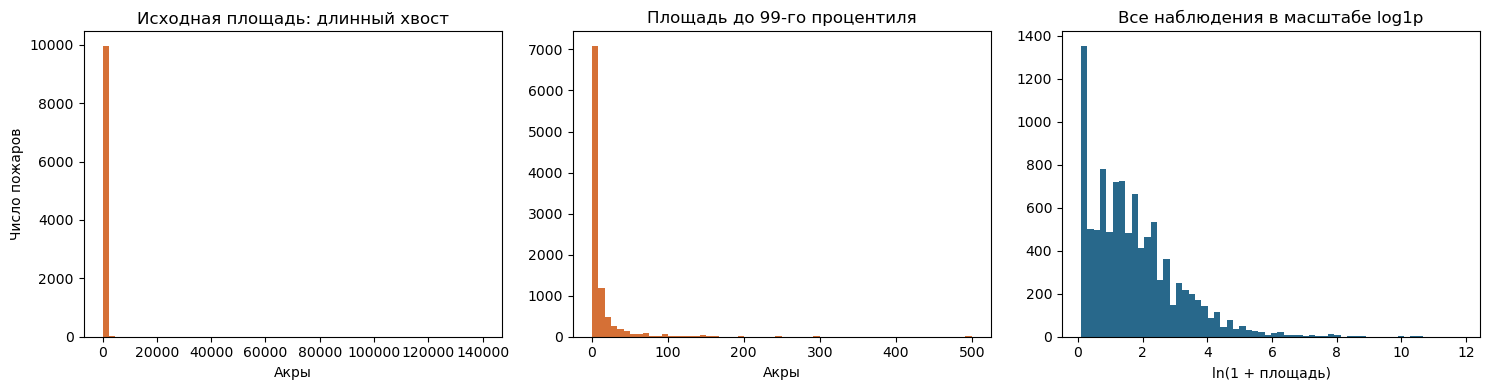

In [50]:
# вероятность распредения данных
area = df[TARGET]
quantiles = area.quantile([0, .25, .5, .75, .9, .95, .99, .999, 1])
display(quantiles.to_frame('площадь, акры'))
print(f'Среднее: {area.mean():.2f}; медиана: {area.median():.2f}; асимметрия: {area.skew():.2f}')
tail_table = pd.DataFrame([
    {'условие': f'площадь ≥ {t} акров', 'число': int((area >= t).sum()),
     'доля_%': 100 * (area >= t).mean()} for t in [10, 100, 1000, 10000]
])
display(tail_table)
top_1_share = area.nlargest(max(1, int(np.ceil(len(area) * .01)))).sum() / area.sum()
print(f'На 1% крупнейших пожаров приходится {top_1_share:.1%} суммарной площади.')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(area, bins=60, color='#d57036')
axes[0].set(title='Исходная площадь: длинный хвост', xlabel='Акры', ylabel='Число пожаров')
# Ограничение оси - только визуализация, строки из обучения не удаляем.
axes[1].hist(area[area <= area.quantile(.99)], bins=60, color='#d57036')
axes[1].set(title='Площадь до 99-го процентиля', xlabel='Акры')
axes[2].hist(np.log1p(area), bins=60, color='#28688b')
axes[2].set(title='Все наблюдения в масштабе log1p', xlabel='ln(1 + площадь)')
fig.tight_layout()
plt.show()

### Выбор масштаба
Обучаем три модели на `z = ln(1 + площадь)`. Единица в формуле — одна числовая единица
площади (акр); преобразование допускает нулевую площадь. Большие пожары остаются в данных,
но их квадрат ошибки не подавляет обучение на остальных возгораниях.
Для использования возвращаем прогноз в акры через `expm1(z)` и ограничиваем снизу нулём.

Это **не превращает распределение автоматически в нормальное** и не устраняет сложность
редких пожаров. `expm1(E[ln(1 + Y)|X])` обычно ниже `E[Y|X]`: обратный прогноз —
геометрическая характеристика `1 + Y`, не несмещённое среднее в акрах и не обязательно медиана.
Поэтому наряду с RMSLE считаем MAE/RMSE в акрах и отдельно измеряем недооценку крупных пожаров.
Обычный MAPE неудобен для очень малых площадей и не определён при нулевой площади.


,n,median_acres,mean_acres,p99_acres,max_acres,median_delay_hours,missing_fuel_pct,missing_rain_pct
discovery_year,,,,,,,,
2019,1240,3.0,100.16,199.22,103100.0,1.9,4.68,2.18
2020,2217,3.4,123.97,421.00,140000.0,2.1,5.46,2.03
2021,2179,3.3,42.11,539.62,20880.0,2.0,3.49,3.53
2022,1432,3.4,181.47,796.23,80300.0,2.4,6.15,2.93
2023,1163,3.0,39.27,488.46,8830.0,1.4,4.21,2.15
2024,1769,3.2,79.83,497.28,41130.0,1.5,4.69,2.43


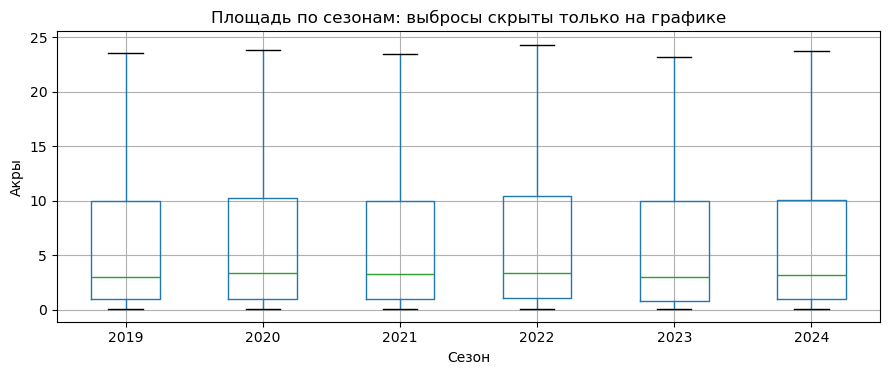

In [51]:
# Это нам для временного разделения и диагностики.
df['discovery_year'] = df.discovery_date.dt.year 
season_table = df.groupby('discovery_year').agg(
    n=(TARGET, 'size'), median_acres=(TARGET, 'median'), mean_acres=(TARGET, 'mean'),
    p99_acres=(TARGET, lambda s: s.quantile(.99)), max_acres=(TARGET, 'max'),
    median_delay_hours=('detection_delay_hours', 'median'),
    missing_fuel_pct=('fuel_moisture_pct', lambda s: 100 * s.isna().mean()),
    missing_rain_pct=('days_since_rain', lambda s: 100 * s.isna().mean()))
display(season_table.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
df.boxplot(column=TARGET, by='discovery_year', ax=ax, showfliers=False)
ax.set(title='Площадь по сезонам: выбросы скрыты только на графике',
       xlabel='Сезон', ylabel='Акры')
fig.suptitle('')
fig.tight_layout()
plt.show()

## 2. Отбор признаков по времени доступности
Доступность устанавливается **из смысла поля и сценария**, а не по высокой корреляции с площадью.
CSV не содержит времени внесения каждого значения. Для основной модели принимаем,
что погода, топливо и география действительно относятся к первому сообщению.
Их доступность нужно подтвердить в системе службы; позднее исправленные значения могут дать утечку.


In [52]:
availability_rows = [
    ('fire_id', 'Исключить', 'Технический ID события; не переносимый фактор роста пожара.'),
    ('discovery_date', 'Преобразовать', 'Дата известна сразу; используем циклический день года.'),
    ('state', 'Использовать', 'Штат определяется по координатам обнаружения.'),
    ('dispatch_unit', 'Использовать условно', 'Только территория ответственности на момент сообщения, не итоговый исполнитель.'),
    ('fuel_model', 'Использовать', 'Карта топлива, доступная на момент обнаружения.'),
    ('cause', 'Исключить', 'Подтверждённая причина часто появляется после расследования; ранняя версия не выделена.'),
    ('temperature_f', 'Использовать', 'Температура на момент обнаружения.'),
    ('relative_humidity_pct', 'Использовать', 'Относительная влажность на момент обнаружения.'),
    ('wind_speed_mph', 'Использовать', 'Ветер на момент обнаружения.'),
    ('days_since_rain', 'Использовать', 'История осадков, известная к моменту сообщения.'),
    ('fuel_moisture_pct', 'Использовать', 'Текущая оценка влажности топлива; пропуск допустим.'),
    ('energy_release_component', 'Использовать', 'Расчётный индекс, опубликованный к моменту сообщения.'),
    ('elevation_ft', 'Использовать', 'Высота из карты местности.'),
    ('slope_deg', 'Использовать', 'Уклон из карты местности.'),
    ('distance_to_road_mi', 'Использовать', 'Расстояние из доступной карты дорог.'),
    ('distance_to_town_mi', 'Использовать', 'Расстояние из доступной карты населённых пунктов.'),
    ('detection_delay_hours', 'Исключить', 'Нужно время начала пожара; точная ретроспективная задержка не гарантирована при обнаружении.'),
    ('crews_dispatched', 'Исключить', 'Результат отправки сил: находится после решаемого выбора; возможно суммарное число за весь пожар.'),
    (TARGET, 'Только целевая переменная', 'Итоговая площадь становится известна после завершения пожара.'),
]
availability = pd.DataFrame(availability_rows, columns=['столбец', 'решение', 'обоснование'])
display(availability)

,столбец,решение,обоснование
0,fire_id,Исключить,Технический ID события; не переносимый фактор ...
1,discovery_date,Преобразовать,Дата известна сразу; используем циклический де...
2,state,Использовать,Штат определяется по координатам обнаружения.
3,dispatch_unit,Использовать условно,Только территория ответственности на момент со...
4,fuel_model,Использовать,"Карта топлива, доступная на момент обнаружения."
5,cause,Исключить,Подтверждённая причина часто появляется после ...
6,temperature_f,Использовать,Температура на момент обнаружения.
7,relative_humidity_pct,Использовать,Относительная влажность на момент обнаружения.
8,wind_speed_mph,Использовать,Ветер на момент обнаружения.
9,days_since_rain,Использовать,"История осадков, известная к моменту сообщения."


`cause` и `detection_delay_hours` не объявляем заведомо недоступными во всех службах:
очевидная причина или оценка времени начала иногда известны сразу. Здесь нет отдельного
раннего поля и подтверждения времени фиксации, поэтому применяем консервативный отбор.
Если `dispatch_unit` — поздний исполнитель, его также нужно убрать из `categorical_features`.
Штат и подразделение частично дублируют географию; это учитывает регуляризация линейной модели.

С 2023 года изменились мониторинг и топливные разрывы. Расстояние до дороги не сообщает,
есть ли конкретный разрыв и когда он создан. В таблице нет этих полей, поэтому нельзя
приписывать изменения площади причинному эффекту программы.


In [53]:
# Сезонность известна в момент обнаружения. Синус и косинус не создают разрыва на границе года.
day = df.discovery_date.dt.dayofyear
days_in_year = np.where(df.discovery_date.dt.is_leap_year, 366, 365)
df['season_sin'] = np.sin(2 * np.pi * (day - 1) / days_in_year)
df['season_cos'] = np.cos(2 * np.pi * (day - 1) / days_in_year)
numeric_features = ['temperature_f', 'relative_humidity_pct', 'wind_speed_mph',
                    'days_since_rain', 'fuel_moisture_pct', 'energy_release_component',
                    'elevation_ft', 'slope_deg', 'distance_to_road_mi',
                    'distance_to_town_mi', 'season_sin', 'season_cos']
categorical_features = ['state', 'dispatch_unit', 'fuel_model']
FEATURES = numeric_features + categorical_features
forbidden = ['fire_id', 'cause', 'detection_delay_hours', 'crews_dispatched', TARGET]
assert not set(FEATURES).intersection(forbidden)
X = df[FEATURES].copy()
y = df[TARGET].copy()

# Будущее не смешиваем с прошлым: модель до изменений проверяется на сезоне 2023.
train_mask = df.discovery_year <= 2022
val_mask = df.discovery_year == 2023
test_mask = df.discovery_year == 2024
assert (train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int) == 1).all()
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]
assert df.loc[train_mask, 'discovery_date'].max() < df.loc[val_mask, 'discovery_date'].min()
assert df.loc[val_mask, 'discovery_date'].max() < df.loc[test_mask, 'discovery_date'].min()
display(pd.DataFrame({'период': ['2019–2022: обучение', '2023: выбор модели', '2024: итоговая проверка'],
                      'число пожаров': [len(y_train), len(y_val), len(y_test)]}))
print('Входов до кодирования:', len(FEATURES))

,период,число пожаров
0,2019–2022: обучение,7068
1,2023: выбор модели,1163
2,2024: итоговая проверка,1769


Входов до кодирования: 15


Год используем для разделения, а не как идентификатор сезона в модели. Деревья не умеют
продолжать тренд за пределы обучающих лет. Индикатор «после 2023» на обучении 2019–2022
был бы константой и не позволил бы выучить изменение программы.
Общий описательный анализ выше охватывает всю выгрузку; дальнейшие исследовательские
графики зависимостей строим по обучению. Модель выбираем на 2023, а 2024 используем один раз,
после выбора и переобучения на 2019–2023.


,Spearman с log1p площади
distance_to_road_mi,0.503
distance_to_town_mi,0.380
wind_speed_mph,0.345
energy_release_component,0.313
fuel_moisture_pct,-0.289
days_since_rain,0.231
relative_humidity_pct,-0.231
slope_deg,0.183
temperature_f,0.146
season_cos,-0.106


,n,median_acres,p90_acres,mean_log_area
fuel_model,,,,
conifer forest,2915,5.0,50.00,2.00
grassland,804,2.0,20.00,1.46
hardwood forest,267,1.5,9.14,1.17
mixed forest,1093,3.0,25.00,1.65
sagebrush,1282,2.4,19.50,1.45
shrub/chaparral,707,3.8,40.00,1.83


fuel_model,conifer forest,grassland,hardwood forest,mixed forest,sagebrush,shrub/chaparral
wind_bin,,,,,,
"[0.0, 5.0)",514,158,59,238,238,127
"[5.0, 10.0)",1388,391,127,514,604,322
"[10.0, 15.0)",693,165,52,226,291,167
"[15.0, 20.0)",215,65,20,71,104,54
"[20.0, 30.0)",87,22,8,37,40,27
"[30.0, inf)",18,3,1,7,5,10


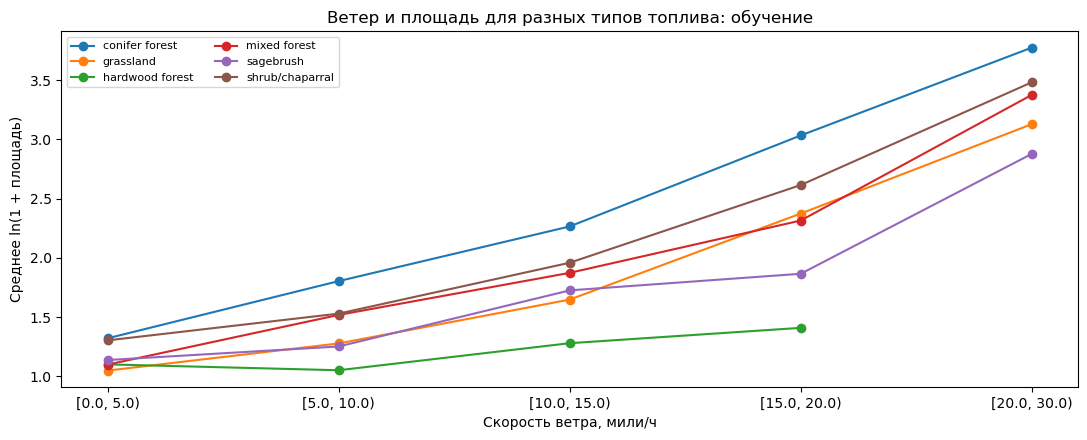

In [54]:
# Анализ зависимостей только на обучении: корреляция не равна причинному эффекту.
train_eda = df.loc[train_mask].copy()
train_eda['log_area'] = np.log1p(train_eda[TARGET])
corr = train_eda[numeric_features + ['log_area']].corr(method='spearman')['log_area'].drop('log_area')
display(corr.sort_values(key=lambda s: s.abs(), ascending=False).to_frame('Spearman с log1p площади').round(3))
fuel_summary = train_eda.groupby('fuel_model').agg(
    n=(TARGET, 'size'), median_acres=(TARGET, 'median'),
    p90_acres=(TARGET, lambda s: s.quantile(.9)), mean_log_area=('log_area', 'mean'))
display(fuel_summary.round(2))

# Фиксированные интервалы служат иллюстрацией возможных порогов; это не правило диспетчера.
train_eda['wind_bin'] = pd.cut(train_eda.wind_speed_mph,
                              bins=[0, 5, 10, 15, 20, 30, np.inf], right=False)
wind_fuel = train_eda.groupby(['wind_bin', 'fuel_model'], observed=True).agg(
    n=('log_area', 'size'), mean_log_area=('log_area', 'mean')).reset_index()
display(wind_fuel.pivot(index='wind_bin', columns='fuel_model', values='n').fillna(0).astype(int))
fig, ax = plt.subplots(figsize=(11, 4.5))
for fuel, part in wind_fuel.groupby('fuel_model'):
    part = part.loc[part.n >= 20]  # Не рисуем среднее по слишком малому числу событий.
    ax.plot(part.wind_bin.astype(str), part.mean_log_area, marker='o', label=fuel)
ax.set(title='Ветер и площадь для разных типов топлива: обучение',
       xlabel='Скорость ветра, мили/ч', ylabel='Среднее ln(1 + площадь)')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

## 3. Базовые модели
Сравниваем **линейную регрессию Ridge**, **одно дерево** и **случайный лес**.
Ridge — линейная модель с небольшой L2-регуляризацией: она стабилизирует коэффициенты
при связанных признаках и категориях. Базовый `alpha=1` здесь не подбираем.
Линейная модель в этой постановке аддитивна и не содержит вручную созданных порогов
или взаимодействий. Дерево и лес могут разделять выборку по порогам ветра и влажности
и автоматически учитывать разные зависимости для типов топлива.

Дополнительно используем константу как точку отсчёта: среднее `log1p` на обучении.
Все модели получают одинаковые исходные признаки и работают в одном масштабе цели.
Для дерева/леса ограничения глубины и размера листа заданы заранее как базовые настройки;
полный подбор параметров и временная кросс-валидация не входят в эти три пункта.


In [55]:
def make_preprocessor(scale_numeric=False):
    steps = [('imputer', SimpleImputer(strategy='median', add_indicator=True))]
    if scale_numeric:
        steps.append(('scaler', StandardScaler()))  # Важно для регуляризации Ridge.
# Медианы и признаки наличия пропусков обучаются внутри Pipeline.
    numeric_pipe = Pipeline(steps)
    categorical_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('num', numeric_pipe, numeric_features),
        ('cat', categorical_pipe, categorical_features)
    ], remainder='drop')

def make_model(estimator, scale_numeric=False):
    pipeline = Pipeline([
        ('prep', make_preprocessor(scale_numeric)),
        ('model', estimator)
    ])
# Обёртка сама преобразует цель при fit и возвращает акры при predict.
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)

model_templates = {
    'Константа': make_model(DummyRegressor(strategy='mean')),
    'Линейная (Ridge)': make_model(Ridge(alpha=1.0), scale_numeric=True),
    'Одно дерево': make_model(DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE)),
    'Случайный лес': make_model(RandomForestRegressor(
        n_estimators=300, max_depth=18, min_samples_leaf=5,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=-1))
}

def predict_acres(model, frame):
    return np.maximum(model.predict(frame), 0)  # Площадь не может быть отрицательной.

def metrics(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return {
        'RMSLE': float(np.sqrt(np.mean((np.log1p(actual) - np.log1p(predicted)) ** 2))),
        'MAE_acres': float(mean_absolute_error(actual, predicted)),
        'RMSE_acres': float(np.sqrt(mean_squared_error(actual, predicted))),
        'R2_log': float(r2_score(np.log1p(actual), np.log1p(predicted))),
        'R2_acres': float(r2_score(actual, predicted)),
        'bias_acres': float(np.mean(predicted - actual)),
        'underestimate_pct': float(100 * np.mean(predicted < actual)),
        'under_by_2x_pct': float(100 * np.mean(predicted < actual / 2)),
    }

**Основная метрика сравнения — RMSLE:** ошибка в масштабе `ln(1 + площадь)`;
меньше — лучше. Она позволяет сравнивать качество на типичных пожарах при длинном хвосте,
но симметрична в логарифмическом масштабе и не отражает повышенную цену недооценки.
MAE — средняя абсолютная ошибка в акрах; RMSE сильнее реагирует на крупные промахи.
`R2_log` и `R2_acres` относятся к разным масштабам, их нельзя взаимозаменять.
Отрицательное R² возможно на будущих сезонах. `bias_acres < 0` означает среднюю недооценку.
`under_by_2x_pct` — доля всех пожаров, для которых прогноз меньше половины фактической площади.


In [56]:
fitted_train = {}
validation_predictions = {}
comparison_rows = []
for name, template in model_templates.items():
    model = clone(template)  # Каждый кандидат начинает обучение с чистого состояния.
    model.fit(X_train, y_train)
    fitted_train[name] = model
    train_pred = predict_acres(model, X_train)
    val_pred = predict_acres(model, X_val)
    validation_predictions[name] = val_pred
    comparison_rows.append({'model': name, 'sample': 'train', **metrics(y_train, train_pred)})
    comparison_rows.append({'model': name, 'sample': 'validation_2023', **metrics(y_val, val_pred)})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

# Выбираем одну из трёх требуемых моделей только по validation 2023, без test 2024.
validation_scores = comparison.query("sample == 'validation_2023' and model != 'Константа'")
best_name = validation_scores.sort_values('RMSLE').iloc[0]['model']
print('Выбрана по RMSLE на 2023:', best_name)

,model,sample,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,Константа,train,1.3605,105.0487,2561.7406,0.0000,-0.0016,-101.5375,43.3079,27.5467
1,Константа,validation_2023,1.4410,38.4386,334.7272,-0.0007,-0.0108,-34.5981,41.7025,27.4291
2,Линейная (Ridge),train,0.8850,102.7050,2559.4619,0.5769,0.0002,-92.7789,46.2932,22.5241
3,Линейная (Ridge),validation_2023,0.9108,36.4618,342.2725,0.6002,-0.0569,-23.5581,42.5623,22.3560
4,Одно дерево,train,0.8723,100.9990,2550.5924,0.5889,0.0071,-93.4619,45.0057,21.9581
5,Одно дерево,validation_2023,0.9899,35.9667,331.1394,0.5277,0.0108,-26.7057,40.2408,21.8401
6,Случайный лес,train,0.5902,96.4956,2546.5840,0.8118,0.0102,-93.7635,43.0249,10.5971
7,Случайный лес,validation_2023,0.8683,33.3361,328.6283,0.6366,0.0257,-28.3727,38.8650,18.2287


Выбрана по RMSLE на 2023: Случайный лес


In [57]:
# Небольшая проверка выбора масштаба: та же линейная модель на исходной площади.
# Эту справочную модель не используем для изменения уже зафиксированного выбора семейства.
raw_linear = Pipeline([('prep', make_preprocessor(True)), ('model', Ridge(alpha=1.0))])
raw_linear.fit(X_train, y_train)
scale_comparison = pd.DataFrame([
    {'вариант': 'Ridge: обучение на log1p', **metrics(y_val, validation_predictions['Линейная (Ridge)'])},
    {'вариант': 'Ridge: обучение на акрах', **metrics(y_val, predict_acres(raw_linear, X_val))}
])
display(scale_comparison.round(4))
print('Масштаб меняет компромисс между точностью типичных пожаров и крупных событий.')

,вариант,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,Ridge: обучение на log1p,0.9108,36.4618,342.2725,0.6002,-0.0569,-23.5581,42.5623,22.3560
1,Ridge: обучение на акрах,2.5963,180.9120,462.3540,-2.2488,-0.9286,138.6402,45.9157,45.3998


Масштаб меняет компромисс между точностью типичных пожаров и крупных событий.


,feature,RMSLE_increase,std
8,distance_to_road_mi,0.4239,0.0060
2,wind_speed_mph,0.2933,0.0172
5,energy_release_component,0.1113,0.0075
7,slope_deg,0.0796,0.0071
9,distance_to_town_mi,0.0285,0.0021
4,fuel_moisture_pct,0.0215,0.0108
1,relative_humidity_pct,0.0068,0.0074
14,fuel_model,0.0054,0.0010
0,temperature_f,0.0044,0.0008
3,days_since_rain,0.0044,0.0022


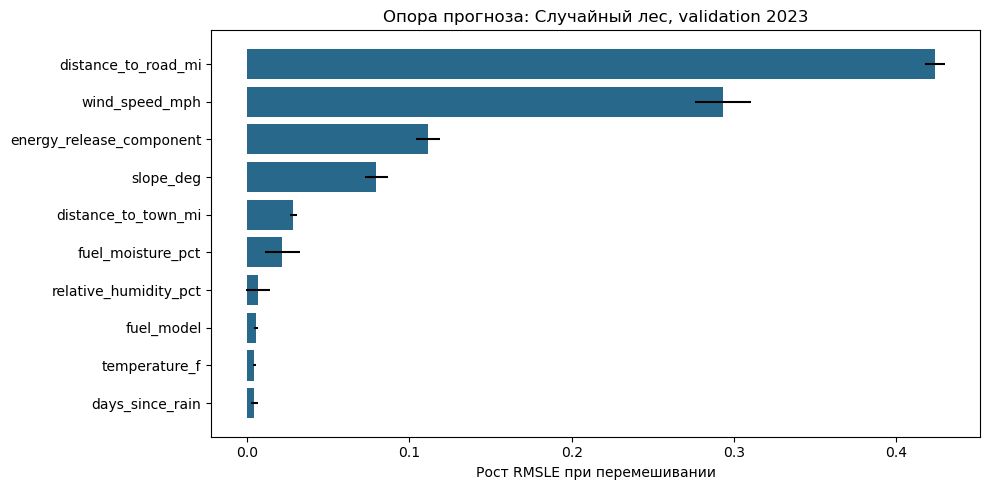

In [58]:
# На что опирается выбранная модель: перемешиваем вход по очереди на validation.
# Потеря RMSLE измеряет полезность признака для прогноза, а не причинный эффект.
def neg_rmsle(estimator, frame, actual):
    return -metrics(actual, predict_acres(estimator, frame))['RMSLE']

importance_result = permutation_importance(
    fitted_train[best_name], X_val, y_val, scoring=neg_rmsle,
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance_table = pd.DataFrame({
    'feature': FEATURES, 'RMSLE_increase': importance_result.importances_mean,
    'std': importance_result.importances_std}).sort_values('RMSLE_increase', ascending=False)
display(importance_table.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
shown = importance_table.head(10).sort_values('RMSLE_increase')
ax.barh(shown.feature, shown.RMSLE_increase, xerr=shown['std'], color='#28688b')
ax.set(title=f'Опора прогноза: {best_name}, validation 2023', xlabel='Рост RMSLE при перемешивании')
fig.tight_layout()
plt.show()

Важность измерена на следующем сезоне для выбранной модели, обученной до 2023.
Связанные признаки могут заменять друг друга: например, штат и подразделение,
влажность топлива и дни без дождя. Поэтому малая индивидуальная важность не означает,
что фактор физически не влияет на пожар. Разброс по пяти перемешиваниям — не доверительный
интервал по новым сезонам. Отрицательная важность означает отсутствие устойчивого улучшения
на этой проверке. После перехода на новые системы ранжирование может измениться.


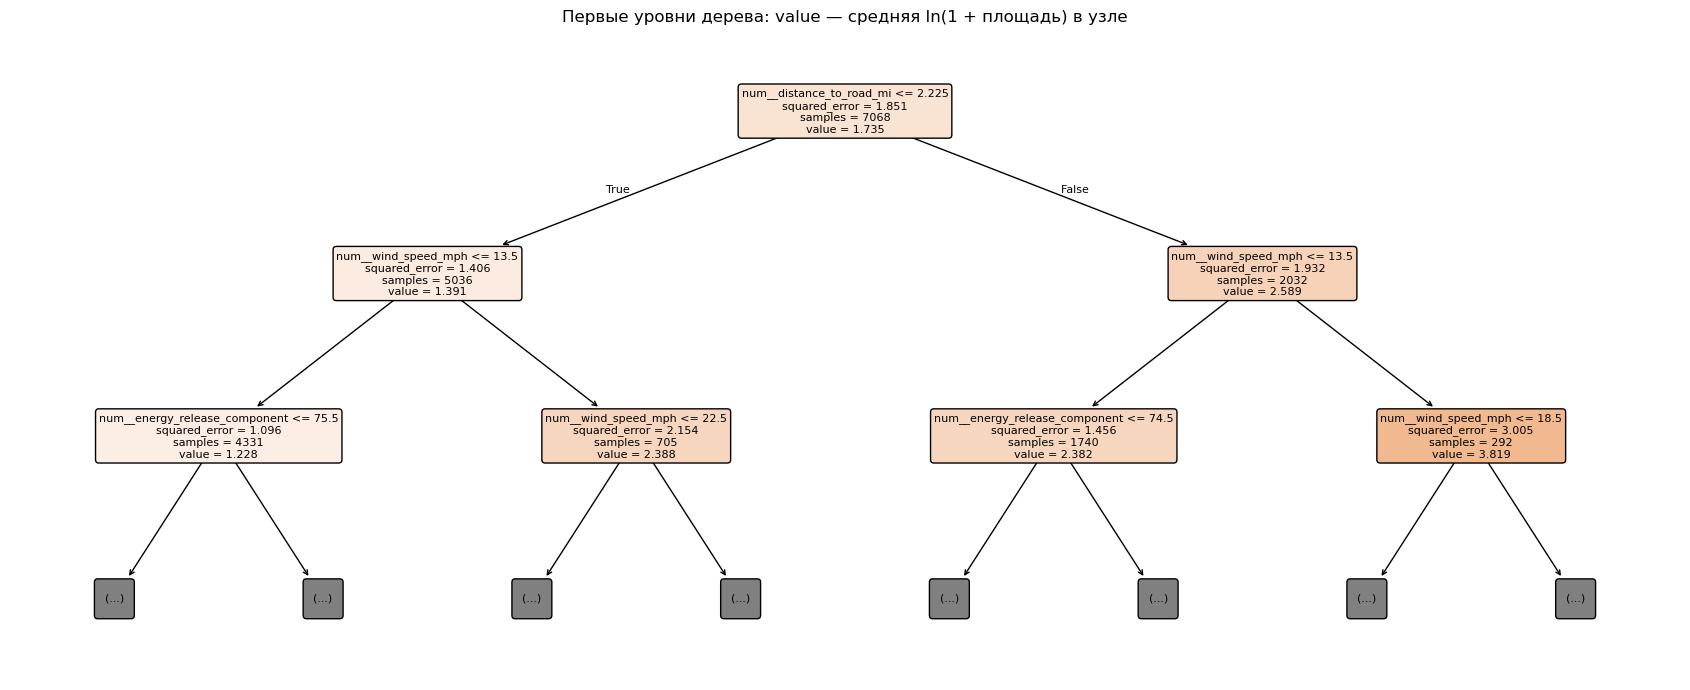

In [59]:
# Визуализируем первые уровни одиночного дерева: ветвления показывают пороговые правила.
tree_pipeline = fitted_train['Одно дерево'].regressor_
feature_names = tree_pipeline.named_steps['prep'].get_feature_names_out()
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(tree_pipeline.named_steps['model'], feature_names=feature_names,
          max_depth=2, filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Первые уровни дерева: value — средняя ln(1 + площадь) в узле')
fig.tight_layout()
plt.show()

### Итоговая проверка на сезоне 2024
Семейство модели и параметры зафиксированы. Переобучаем кандидатов на 2019–2023,
чтобы включить первый сезон после изменения мониторинга, и один раз оцениваем 2024.
Итоговый лидер сохраняется по выбору на validation, даже если в тестовой таблице
другая модель получит лучшую отдельную метрику. На тесте параметры не корректируем.

Это сохранённая проверка базовых моделей. В разделах 4–7 сезон 2024 уже известен; его используем как историческую внешнюю проверку, а не новый нетронутый тест.


In [60]:
# сравнение и тесты моделей
development_mask = train_mask | val_mask
X_development, y_development = X.loc[development_mask], y.loc[development_mask]
final_models = {}
test_predictions = {}
test_rows = []
for name, template in model_templates.items():
    model = clone(template)
    model.fit(X_development, y_development)
    final_models[name] = model
    predicted = predict_acres(model, X_test)
    assert np.isfinite(predicted).all() and (predicted >= 0).all()
    test_predictions[name] = predicted
    test_rows.append({'model': name, **metrics(y_test, predicted)})
test_comparison = pd.DataFrame(test_rows).set_index('model')
display(test_comparison.round(4))
best_model = final_models[best_name]
best_test_pred = test_predictions[best_name]
print('Зафиксированная модель:', best_name)
print('Новые категории в 2024 (кодировщик обработает их через ignore):')
for col in categorical_features:
    print(col, sorted(set(X_test[col].dropna()) - set(X_development[col].dropna())))

,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
model,,,,,,,,
Константа,1.4202,78.7454,1278.6025,-0.0001,-0.0035,-75.1892,44.5449,28.8298
Линейная (Ridge),0.8947,75.1695,1276.6011,0.6031,-0.0003,-68.8481,48.3889,24.0814
Одно дерево,0.9882,75.6363,1272.6948,0.5158,0.0058,-69.3836,46.4104,25.2120
Случайный лес,0.8708,73.7310,1274.4238,0.6240,0.0031,-69.7671,45.5625,21.5941


Зафиксированная модель: Случайный лес
Новые категории в 2024 (кодировщик обработает их через ignore):
state []
dispatch_unit []
fuel_model []


In [61]:
# Диагностика ошибок выбранной модели в акрах, без удаления крупных пожаров.
diagnostics = df.loc[test_mask, ['fire_id', 'discovery_date', 'state', 'fuel_model', TARGET]].copy()
diagnostics['predicted_acres'] = best_test_pred
diagnostics['error_acres'] = diagnostics.predicted_acres - diagnostics[TARGET]
diagnostics['absolute_error_acres'] = diagnostics.error_acres.abs()
diagnostics['log_error'] = np.log1p(diagnostics.predicted_acres) - np.log1p(diagnostics[TARGET])
diagnostics['area_group'] = pd.cut(diagnostics[TARGET],
    bins=[-np.inf, 10, 100, 1000, np.inf], right=False,
    labels=['<10', '10–<100', '100–<1000', '≥1000'])

def summarize_errors(frame, group_col):
    rows = []
    for name, group in frame.groupby(group_col, observed=True, sort=True):
        rows.append({'group': str(name), 'n': len(group),
                     'median_actual_acres': group[TARGET].median(),
                     'median_predicted_acres': group.predicted_acres.median(),
                     **metrics(group[TARGET], group.predicted_acres)})
    return pd.DataFrame(rows)

display(summarize_errors(diagnostics, 'area_group').round(3))
display(summarize_errors(diagnostics, 'fuel_model').round(3))
display(summarize_errors(diagnostics, 'state').round(3))
print('Пять крупнейших недооценок в 2024:')
display(diagnostics.nsmallest(5, 'error_acres').drop(columns='area_group').round(2))

,group,n,median_actual_acres,median_predicted_acres,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,<10,1272,1.80,2.428,0.631,2.116,3.703,0.206,-1.043,0.974,30.110,9.355
1,10–<100,420,18.65,10.199,0.971,15.984,24.022,-1.590,-0.590,-11.108,83.095,47.381
2,100–<1000,64,154.00,42.358,1.547,161.713,199.050,-6.619,-0.649,-145.556,95.312,79.688
3,≥1000,13,2580.00,47.667,4.694,8513.556,14859.176,-14.124,-0.499,-8513.556,100.000,100.000


,group,n,median_actual_acres,median_predicted_acres,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,conifer forest,754,5.00,4.291,0.861,33.339,268.271,0.664,0.152,-29.400,50.398,23.873
1,grassland,183,3.00,3.410,1.122,366.696,3247.464,0.567,-0.010,-364.633,45.902,21.858
2,hardwood forest,65,1.10,2.647,0.814,4.723,8.558,0.382,0.195,1.162,21.538,9.231
3,mixed forest,265,3.00,3.737,0.741,9.939,33.371,0.633,0.119,-4.735,43.019,17.358
4,sagebrush,320,2.45,2.944,0.665,5.728,18.526,0.643,0.281,-2.324,40.000,15.313
5,shrub/chaparral,182,3.00,2.609,1.104,183.591,2209.539,0.470,-0.005,-179.118,47.253,33.516


,group,n,median_actual_acres,median_predicted_acres,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,arizona,159,3.00,3.366,0.900,265.616,3258.119,0.567,-0.004,-261.632,44.025,18.239
1,california,306,2.00,2.811,1.064,188.386,1915.870,0.595,-0.003,-181.254,41.503,23.529
2,colorado,158,2.50,2.713,0.663,8.674,38.057,0.691,0.302,-6.421,43.671,15.190
3,idaho,188,5.70,4.542,0.870,24.944,143.500,0.618,0.080,-21.338,56.383,25.000
4,montana,152,5.00,4.738,0.919,66.489,539.189,0.647,0.099,-63.680,53.289,23.684
5,nevada,125,4.50,3.806,0.874,32.293,279.434,0.512,-0.001,-28.703,46.400,20.800
6,new mexico,120,2.45,3.086,0.766,7.162,19.975,0.588,0.365,-4.016,35.833,20.000
7,oregon,166,4.10,4.150,0.883,23.997,109.649,0.638,0.123,-21.270,51.807,26.506
8,utah,129,2.20,3.548,0.740,7.447,31.087,0.620,0.275,-3.874,35.659,17.054
9,washington,143,4.10,3.767,0.815,21.372,104.492,0.657,0.281,-16.982,45.455,24.476


Пять крупнейших недооценок в 2024:


,fire_id,discovery_date,state,fuel_model,burned_area_acres,predicted_acres,error_acres,absolute_error_acres,log_error
8522,fire-729796,2024-06-03,arizona,grassland,41130.0,47.67,-41082.33,41082.33,-6.74
9469,fire-456719,2024-08-22,california,shrub/chaparral,29790.0,23.01,-29766.99,29766.99,-7.12
9525,fire-651175,2024-08-26,california,grassland,13500.0,80.33,-13419.67,13419.67,-5.11
9680,fire-338507,2024-09-10,california,grassland,7160.0,33.61,-7126.39,7126.39,-5.33
9464,fire-974204,2024-08-21,montana,conifer forest,6870.0,413.40,-6456.60,6456.60,-2.81


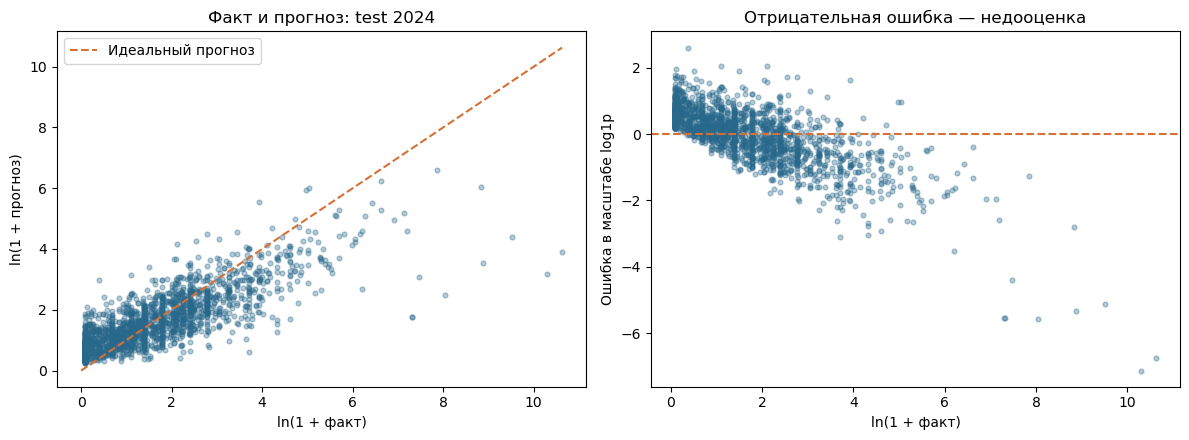

In [62]:
# визуализация отличия прогноза от реальности 
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
actual_log = np.log1p(y_test.to_numpy())
predicted_log = np.log1p(best_test_pred)
axes[0].scatter(actual_log, predicted_log, s=12, alpha=.35, color='#28688b')
upper = max(actual_log.max(), predicted_log.max())
axes[0].plot([0, upper], [0, upper], '--', color='#d57036', label='Идеальный прогноз')
axes[0].set(title='Факт и прогноз: test 2024', xlabel='ln(1 + факт)', ylabel='ln(1 + прогноз)')
axes[0].legend()
axes[1].scatter(actual_log, predicted_log - actual_log, s=12, alpha=.35, color='#28688b')
axes[1].axhline(0, linestyle='--', color='#d57036')
axes[1].set(title='Отрицательная ошибка — недооценка',
            xlabel='ln(1 + факт)', ylabel='Ошибка в масштабе log1p')
fig.tight_layout()
plt.show()

### Предварительное заключение для диспетчерской службы
Следующая ячейка формирует вывод из рассчитанных метрик, без заранее вписанного победителя.
Порог 1000 акров здесь — **диагностическая граница крупного пожара**, а не норматив отправки сил.
По этим данным нельзя обосновать, сколько именно расчётов отправлять, либо вычислить оптимальную
частоту переобучения: неизвестны стоимости ошибок и имеется только шесть сезонов.


In [63]:
# выводы для себя и для вас, просто все выводы суммированы 
selected_metrics = test_comparison.loc[best_name]
val_metrics = validation_scores.set_index('model').loc[best_name]
baseline_rmsle = test_comparison.loc['Константа', 'RMSLE']
relative_gain = 100 * (1 - selected_metrics.RMSLE / baseline_rmsle)
top_features = ', '.join(importance_table.head(5).feature)
large = diagnostics.loc[diagnostics[TARGET] >= 1000]
worst_id = diagnostics.loc[diagnostics.error_acres.idxmin(), 'fire_id']
print(f'Выбрана модель: {best_name}.')
print(f'Опора прогноза по validation 2023: {top_features}.')
print(f'В 2024 RMSLE = {selected_metrics.RMSLE:.3f}, MAE = {selected_metrics.MAE_acres:.2f} акра, '
      f'RMSE = {selected_metrics.RMSE_acres:.2f} акра.')
print(f'R² в log1p = {selected_metrics.R2_log:.3f}; R² в акрах = {selected_metrics.R2_acres:.3f}. '
      'При R² в акрах около нуля способность объяснять разброс реальной площади остаётся слабой.')
print(f'Изменение RMSLE относительно константы: улучшение на {relative_gain:.1f}% '
      '(отрицательное значение означало бы ухудшение).')
print(f'Среднее смещение = {selected_metrics.bias_acres:.2f} акра; '
      f'недооценка более чем вдвое у {selected_metrics.under_by_2x_pct:.1f}% всех пожаров.')
if len(large):
    severe = (large.predicted_acres < large[TARGET] / 2).mean()
    print(f'Для {len(large)} пожаров от 1000 акров недооценка более чем вдвое: {severe:.1%}.')
print(f'Крупнейшая недооценка в тесте: {worst_id}.')
print(f'RMSLE на 2023 = {val_metrics.RMSLE:.3f}; на 2024 после обновления = {selected_metrics.RMSLE:.3f}.')
print('Эти две оценки относятся к разным сезонам и разному объёму обучения; '
      'их отличие не является чистой оценкой эффекта переобучения.')
# вот по пожарам я без понятия, поэтому и цену ошибки пока дать не могу, после сдачи как подумаю насчёт ошибки - исправлю
print('Для решения об отправке сил требуется учесть цену недооценки и доступные расчёты; '
      'средний точечный прогноз не задаёт безопасную верхнюю границу площади.')

Выбрана модель: Случайный лес.
Опора прогноза по validation 2023: distance_to_road_mi, wind_speed_mph, energy_release_component, slope_deg, distance_to_town_mi.
В 2024 RMSLE = 0.871, MAE = 73.73 акра, RMSE = 1274.42 акра.
R² в log1p = 0.624; R² в акрах = 0.003. При R² в акрах около нуля способность объяснять разброс реальной площади остаётся слабой.
Изменение RMSLE относительно константы: улучшение на 38.7% (отрицательное значение означало бы ухудшение).
Среднее смещение = -69.77 акра; недооценка более чем вдвое у 21.6% всех пожаров.
Для 13 пожаров от 1000 акров недооценка более чем вдвое: 100.0%.
Крупнейшая недооценка в тесте: fire-729796.
RMSLE на 2023 = 0.868; на 2024 после обновления = 0.871.
Эти две оценки относятся к разным сезонам и разному объёму обучения; их отличие не является чистой оценкой эффекта переобучения.
Для решения об отправке сил требуется учесть цену недооценки и доступные расчёты; средний точечный прогноз не задаёт безопасную верхнюю границу площади.


## 4. Градиентный бустинг: скорость обучения, сложность и early stopping
Используем `GradientBoostingRegressor` на `log1p(площадь)`. Каждое новое дерево
исправляет остаточную ошибку ансамбля. Малая `learning_rate` уменьшает вклад дерева,
но обычно требует больше итераций. Глубина дерева регулирует сложность взаимодействий.

Сетка: `learning_rate ∈ {0.03, 0.08, 0.15}`, `max_depth ∈ {2, 3, 5}`,
минимум 20 событий в листе. Вместе подбираем число деревьев с **временным early stopping**:
обучение 2019–2022, контроль 2023. Добавляем по 10 деревьев, максимум 600;
останавливаемся после 40 деревьев без улучшения RMSLE хотя бы на 0.0001.
Это контроль по блокам, оптимальное число деревьев кратно 10.
Встроенный случайный `validation_fraction` отключён. Препроцессор не видит 2023 при обучении.
Для выбранного кандидата заново обучаем ровно лучшее число деревьев: последних лишних деревьев
после оптимума в используемой модели не будет.

Общий сезон для early stopping и подбора даёт оптимистичную оценку на 2023.
В разделе 6 отдельно проверяем устойчивость схемы на нескольких сезонах.


In [64]:
# снова обучаем только по-другому принципу 
def fit_boost_with_time_stop(X_fit, y_fit, X_stop, y_stop,
                             learning_rate, max_depth, max_trees=600,
                             block_size=10, patience_trees=40, tolerance=0.0001):
    start = perf_counter()
    prep = make_preprocessor(False)
    Z_fit = prep.fit_transform(X_fit)  # Медианы и категории только по прошлому.
    Z_stop = prep.transform(X_stop)
    log_fit, log_stop = np.log1p(y_fit.to_numpy()), np.log1p(y_stop.to_numpy())
    boost = GradientBoostingRegressor(
        learning_rate=learning_rate, max_depth=max_depth,
        min_samples_leaf=20, n_estimators=block_size, warm_start=True,
        n_iter_no_change=None, random_state=RANDOM_STATE)
    history, best_score, patience_score = [], np.inf, np.inf
    best_trees, stale_trees = block_size, 0
    for n in range(block_size, max_trees + 1, block_size):
        boost.set_params(n_estimators=n)
        boost.fit(Z_fit, log_fit)  # warm_start добавляет деревья к тому же ансамблю.
        stop_prediction = np.maximum(boost.predict(Z_stop), 0)
        stop_rmsle = float(np.sqrt(np.mean((log_stop - stop_prediction) ** 2)))
        fit_rmsle = float(np.sqrt(np.mean((log_fit - np.maximum(boost.predict(Z_fit), 0)) ** 2)))
        history.append({'n_trees':n, 'train_RMSLE':fit_rmsle, 'stop_RMSLE':stop_rmsle})
        if stop_rmsle < best_score:
            best_score, best_trees = stop_rmsle, n  # Сохраняем точный минимум среди блоков.
        if stop_rmsle < patience_score - tolerance:
            patience_score, stale_trees = stop_rmsle, 0
        else:
            stale_trees += block_size
        if stale_trees >= patience_trees:
            break
    return {'best_trees':best_trees, 'best_RMSLE':best_score,
            'fitted_trees':n, 'stopped_early':n < max_trees,
            'search_seconds':perf_counter()-start,
            'history':pd.DataFrame(history)}

boost_grid_rows, boost_histories = [], {}
for lr, depth in product([0.03, 0.08, 0.15], [2, 3, 5]):
    result = fit_boost_with_time_stop(X_train, y_train, X_val, y_val, lr, depth)
    boost_histories[(lr, depth)] = result.pop('history')
    boost_grid_rows.append({'learning_rate':lr, 'max_depth':depth, **result})
boost_grid = pd.DataFrame(boost_grid_rows).sort_values('best_RMSLE').reset_index(drop=True)
display(boost_grid.round(4))
selected_boost = boost_grid.iloc[0]
boost_params = {'learning_rate':float(selected_boost.learning_rate),
                'max_depth':int(selected_boost.max_depth),
                'min_samples_leaf':20, 'n_estimators':int(selected_boost.best_trees),
                'n_iter_no_change':None, 'random_state':RANDOM_STATE}
boost_template = make_model(GradientBoostingRegressor(**boost_params))
boost_train = clone(boost_template).fit(X_train, y_train)
boost_val_pred = predict_acres(boost_train, X_val)
assert abs(metrics(y_val, boost_val_pred)['RMSLE'] - selected_boost.best_RMSLE) < 1e-8
print('Выбранные параметры:', boost_params)
print(f'Время всего поиска: {boost_grid.search_seconds.sum():.2f} с; '
      'не включает последующее переобучение выбранной модели.')

,learning_rate,max_depth,best_trees,best_RMSLE,fitted_trees,stopped_early,search_seconds
0,0.08,5,130,0.8591,170,True,5.5696
1,0.08,3,250,0.8605,260,True,5.4315
2,0.03,3,570,0.8612,600,False,14.1392
3,0.08,2,370,0.8613,390,True,5.8019
4,0.03,5,350,0.8620,350,True,12.9556
5,0.15,2,210,0.8631,250,True,3.4792
6,0.03,2,600,0.8646,600,False,10.0065
7,0.15,5,70,0.8656,100,True,3.2694
8,0.15,3,110,0.8664,150,True,2.9803


Выбранные параметры: {'learning_rate': 0.08, 'max_depth': 5, 'min_samples_leaf': 20, 'n_estimators': 130, 'n_iter_no_change': None, 'random_state': 42}
Время всего поиска: 63.63 с; не включает последующее переобучение выбранной модели.


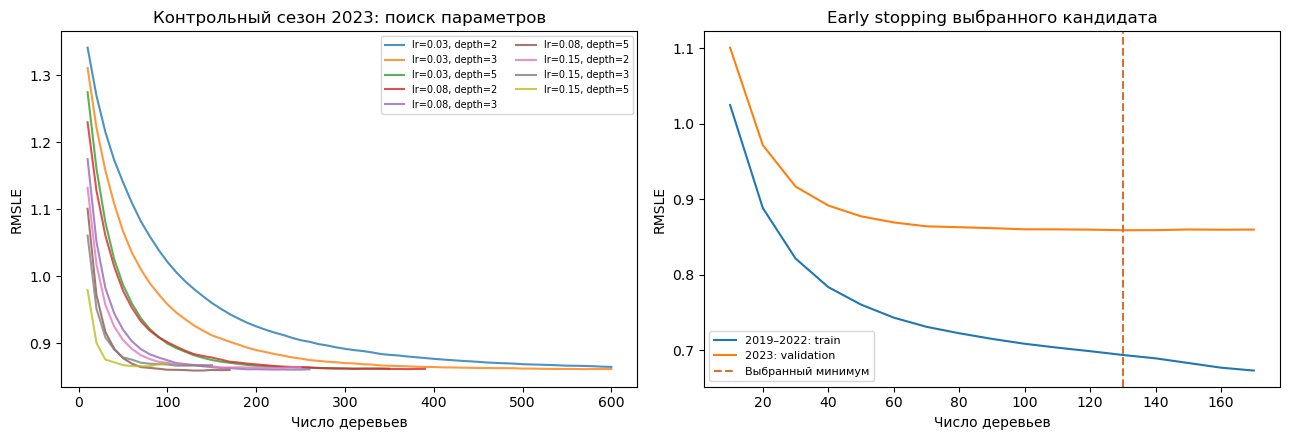

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (lr, depth), history in boost_histories.items():
    axes[0].plot(history.n_trees, history.stop_RMSLE,
                 label=f'lr={lr}, depth={depth}', alpha=.8)
axes[0].set(title='Контрольный сезон 2023: поиск параметров',
            xlabel='Число деревьев', ylabel='RMSLE')
axes[0].legend(fontsize=7, ncol=2)
selected_history = boost_histories[(boost_params['learning_rate'], boost_params['max_depth'])]
axes[1].plot(selected_history.n_trees, selected_history.train_RMSLE, label='2019–2022: train')
axes[1].plot(selected_history.n_trees, selected_history.stop_RMSLE, label='2023: validation')
axes[1].axvline(boost_params['n_estimators'], linestyle='--', color='#d57036', label='Выбранный минимум')
axes[1].set(title='Early stopping выбранного кандидата', xlabel='Число деревьев', ylabel='RMSLE')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Качество и время относительно базовых моделей
Выбор между семействами делаем по RMSLE на 2023, добавив настроенный бустинг к трём
базовым моделям. Базовые модели имеют прежние фиксированные настройки: преимущество
бустинга отражает и алгоритм, и дополнительный бюджет подбора.

Время измеряем отдельно на одинаковых 2019–2023 годах: **три полных fit с препроцессором**,
медиана и разброс, без поиска параметров. В этом сравнении используем один вычислительный
поток, для леса задаём `n_jobs=1`. Это устраняет преимущество леса за счёт числа потоков.
Время зависит от машины, версий и нагрузки; это не оценка времени тушения или работы службы.
Дополнительно измеряем прогноз всех 1769 событий 2024; вывод в миллисекундах на событие
служит приблизительным ориентиром для пакетного прогнозирования, без расходов системы связи.


In [66]:
# сравнение как это выше
expanded_templates = {**model_templates, 'Градиентный бустинг':boost_template}
expanded_val_rows = validation_scores.drop(columns='sample').to_dict('records')
expanded_val_rows.append({'model':'Градиентный бустинг', **metrics(y_val, boost_val_pred)})
expanded_validation = pd.DataFrame(expanded_val_rows).sort_values('RMSLE').set_index('model')
expanded_best_name = expanded_validation.index[0]  # Выбор по 2023, не по 2024.
display(expanded_validation.round(4))
print('Выбор среди четырёх моделей по 2023:', expanded_best_name)

timing_rows, expanded_final_models, expanded_test_rows = [], {}, []
BENCHMARK_REPEATS = 3
for name, template in expanded_templates.items():
    fit_times, predict_times = [], []
    with threadpool_limits(limits=1):
        for repeat in range(BENCHMARK_REPEATS):
            timed_model = clone(template)
            if name == 'Случайный лес':
                timed_model.set_params(regressor__model__n_jobs=1)
            start = perf_counter()
            timed_model.fit(X_development, y_development)
            fit_times.append(perf_counter()-start)
            start = perf_counter()
            prediction = predict_acres(timed_model, X_test)
            predict_times.append(perf_counter()-start)
    expanded_final_models[name] = timed_model
    expanded_test_rows.append({'model':name, **metrics(y_test, prediction)})
    timing_rows.append({'model':name, 'fit_median_s':np.median(fit_times),
                       'fit_min_s':np.min(fit_times), 'fit_max_s':np.max(fit_times),
                       'predict_2024_median_s':np.median(predict_times),
                       'predict_ms_per_fire':1000*np.median(predict_times)/len(X_test)})
timing_table = pd.DataFrame(timing_rows).set_index('model')
expanded_test = pd.DataFrame(expanded_test_rows).set_index('model')
quality_time = expanded_test.join(timing_table)
quality_time['fit_time_vs_forest'] = quality_time.fit_median_s / quality_time.loc['Случайный лес','fit_median_s']
display(quality_time.round(4))
print('Полное время поиска бустинга указано отдельно:', round(boost_grid.search_seconds.sum(), 2), 'с')

,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
model,,,,,,,,
Градиентный бустинг,0.8591,32.8459,324.2866,0.6443,0.0513,-25.2929,40.3267,17.9708
Случайный лес,0.8683,33.3361,328.6283,0.6366,0.0257,-28.3727,38.8650,18.2287
Линейная (Ridge),0.9108,36.4618,342.2725,0.6002,-0.0569,-23.5581,42.5623,22.3560
Одно дерево,0.9899,35.9667,331.1394,0.5277,0.0108,-26.7057,40.2408,21.8401


Выбор среди четырёх моделей по 2023: Градиентный бустинг


,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct,fit_median_s,fit_min_s,fit_max_s,predict_2024_median_s,predict_ms_per_fire,fit_time_vs_forest
model,,,,,,,,,,,,,,
Константа,1.4202,78.7454,1278.6025,-0.0001,-0.0035,-75.1892,44.5449,28.8298,0.0256,0.0248,0.0273,0.0066,0.0037,0.0017
Линейная (Ridge),0.8947,75.1695,1276.6011,0.6031,-0.0003,-68.8481,48.3889,24.0814,0.0334,0.0329,0.0345,0.0067,0.0038,0.0022
Одно дерево,0.9882,75.6363,1272.6948,0.5158,0.0058,-69.3836,46.4104,25.2120,0.0806,0.0799,0.0806,0.0070,0.0040,0.0052
Случайный лес,0.8708,73.7310,1274.4238,0.6240,0.0031,-69.7671,45.5625,21.5941,15.5251,15.4344,15.5986,0.0778,0.0440,1.0000
Градиентный бустинг,0.8488,73.9267,1272.5160,0.6428,0.0061,-66.2209,45.9016,21.9898,4.4541,4.4421,4.4755,0.0113,0.0064,0.2869


Полное время поиска бустинга указано отдельно: 63.63 с


,n_large,large_MAE_acres,large_under_by_2x_pct
model,,,
Константа,13,8646.131,100.0
Линейная (Ridge),13,8561.695,100.0
Одно дерево,13,8530.034,100.0
Случайный лес,13,8513.556,100.0
Градиентный бустинг,13,8440.573,100.0


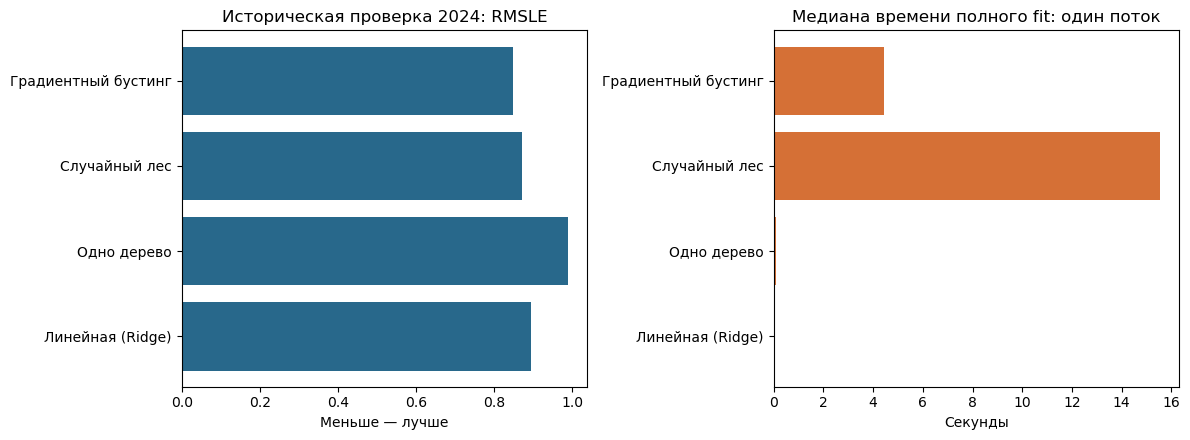

In [67]:
# Отдельная диагностика крупного хвоста для всех моделей, без выбора по тестовому хвосту.
large_mask = y_test >= 1000
tail_rows = []
for name, model in expanded_final_models.items():
    pred = predict_acres(model, X_test)
    tail_rows.append({'model':name, 'n_large':int(large_mask.sum()),
        'large_MAE_acres':mean_absolute_error(y_test.loc[large_mask], pred[large_mask.to_numpy()]),
        'large_under_by_2x_pct':100*np.mean(pred[large_mask.to_numpy()] < y_test.loc[large_mask].to_numpy()/2)})
expanded_tail = pd.DataFrame(tail_rows).set_index('model')
display(expanded_tail.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
shown = quality_time.drop(index='Константа')
axes[0].barh(shown.index, shown.RMSLE, color='#28688b')
axes[0].set(title='Историческая проверка 2024: RMSLE', xlabel='Меньше — лучше')
axes[1].barh(shown.index, shown.fit_median_s, color='#d57036')
axes[1].set(title='Медиана времени полного fit: один поток', xlabel='Секунды')
fig.tight_layout()
plt.show()

## 6. Устойчивость во времени: перелом и схема проверки
Перелом ищем по двум независимым по смыслу наблюдениям:
1. изменения времени обнаружения (диагностическое поле, не вход основной модели);
2. изменение ошибки **одной замороженной модели**, обученной до изменений.

Граница — начало сезона. Для задержки выбираем границу, которая сильнее всего уменьшает
сумму квадратов отклонений `log1p(задержка)` от средних до/после.
При сканировании всей истории оставляем не меньше двух сезонов с каждой стороны.
Это описательный поиск точки сдвига; его результат не доказывает причину изменения
и не является формальным тестом структурного перелома независимых сезонов.


In [33]:
# Также сравнение, но уже, если можно так сказать, между границами сезонов
def scan_season_break(years, values, min_seasons_each_side=2):
    years, values = np.asarray(years), np.asarray(values)
    unique_years = np.sort(np.unique(years))
    total_sse = np.sum((values-values.mean())**2)
    rows = []
    for boundary in unique_years[1:]:
        before, after = years < boundary, years >= boundary
        if (len(np.unique(years[before])) < min_seasons_each_side or
            len(np.unique(years[after])) < min_seasons_each_side):
            continue
        sse = np.sum((values[before]-values[before].mean())**2)
        sse += np.sum((values[after]-values[after].mean())**2)
        rows.append({'break_year':int(boundary), 'n_before':int(before.sum()),
                     'n_after':int(after.sum()), 'mean_before':values[before].mean(),
                     'mean_after':values[after].mean(),
                     'mean_shift':values[after].mean()-values[before].mean(),
                     'SSE_reduction':total_sse-sse,
                     'SSE_reduction_pct':100*(total_sse-sse)/total_sse})
    return pd.DataFrame(rows).sort_values('SSE_reduction', ascending=False)

delay_break_scan = scan_season_break(df.discovery_year, np.log1p(df.detection_delay_hours))
delay_break_year = int(delay_break_scan.iloc[0].break_year)
display(delay_break_scan.round(4))
before_break, after_break = df.discovery_year < delay_break_year, df.discovery_year >= delay_break_year
shift_rows = []
for feature in ['detection_delay_hours', 'distance_to_road_mi', 'wind_speed_mph',
                'fuel_moisture_pct', 'energy_release_component', TARGET]:
    before = df.loc[before_break, feature].dropna()
    after = df.loc[after_break, feature].dropna()
    iqr = before.quantile(.75)-before.quantile(.25)
    shift_rows.append({'feature':feature, 'median_before':before.median(),
                      'median_after':after.median(), 'mean_before':before.mean(),
                      'mean_after':after.mean(),
                      'median_shift_in_before_IQR':(after.median()-before.median())/iqr if iqr else np.nan})
shift_table = pd.DataFrame(shift_rows).set_index('feature')
display(shift_table.round(4))
print('Наибольший сдвиг log1p задержки при границе:', delay_break_year)
print(f'Медианы задержки в соседних сезонах: '
      f'{df.loc[df.discovery_year==delay_break_year-1,"detection_delay_hours"].median():.2f} → '
      f'{df.loc[df.discovery_year==delay_break_year,"detection_delay_hours"].median():.2f} часа.')

# Проверяем устойчивость точки к исключению отдельного штата из анализа.
state_sensitivity = []
for excluded_state in sorted(df.state.unique()):
    kept = df.state != excluded_state
    scan = scan_season_break(df.loc[kept,'discovery_year'], np.log1p(df.loc[kept,'detection_delay_hours']))
    state_sensitivity.append({'excluded_state':excluded_state, 'break_year':int(scan.iloc[0].break_year)})
display(pd.DataFrame(state_sensitivity))

,break_year,n_before,n_after,mean_before,mean_after,mean_shift,SSE_reduction,SSE_reduction_pct
2,2023,7068,2932,1.281,1.0904,-0.1905,75.2170,1.2519
0,2021,3457,6543,1.279,1.1966,-0.0824,15.3541,0.2555
1,2022,5636,4364,1.256,1.1852,-0.0708,12.3121,0.2049


,median_before,median_after,mean_before,mean_after,median_shift_in_before_IQR
feature,,,,,
detection_delay_hours,2.10,1.50,4.9439,3.6395,-0.2143
distance_to_road_mi,1.27,1.26,1.8643,1.8820,-0.0055
wind_speed_mph,8.00,8.00,8.6692,8.7650,0.0000
fuel_moisture_pct,10.20,10.30,11.3772,11.6644,0.0217
energy_release_component,49.00,49.00,49.1324,48.8973,0.0000
burned_area_acres,3.30,3.00,106.2073,63.7392,-0.0333


Наибольший сдвиг log1p задержки при границе: 2023
Медианы задержки в соседних сезонах: 2.40 → 1.40 часа.


,excluded_state,break_year
0,arizona,2023
1,california,2023
2,colorado,2023
3,idaho,2023
4,montana,2023
5,nevada,2023
6,new mexico,2023
7,oregon,2023
8,utah,2023
9,washington,2023


,n,mean_log_residual,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
year,,,,,,,,,,
2021,2179,-0.0408,0.8579,36.1185,491.2756,0.5992,0.0260,-29.0540,43.6898,19.4585
2022,1432,0.0792,0.9507,174.8052,2958.7142,0.5587,-0.0018,-170.0644,49.5810,24.7207
2023,1163,-0.0473,0.8709,32.8414,328.5849,0.6345,0.0260,-27.4954,41.0146,20.3783
2024,1769,0.0442,0.8685,73.2525,1273.0783,0.6260,0.0052,-69.2791,46.4669,23.7988


,break_year,n_before,n_after,mean_before,mean_after,mean_shift,SSE_reduction,SSE_reduction_pct
0,2022,2179,4364,-0.0408,0.0313,0.0721,7.5492,0.1476
2,2024,4774,1769,-0.0064,0.0442,0.0505,3.2947,0.0644
1,2023,3611,2932,0.0068,0.0079,0.0011,0.0018,0.0000


,period,road_group,n,mean_log_residual,median_acres
0,2021–2022,<2 mi,2409,0.0008,2.0
1,2021–2022,≥2 mi,1202,0.0188,8.2
2,2023–2024,<2 mi,1992,-0.1201,1.8
3,2023–2024,≥2 mi,940,0.2792,10.4


Сдвиг среднего остатка у дорог: -0.1210; вдали: 0.2604; разность сдвигов: -0.3813 в масштабе log1p.


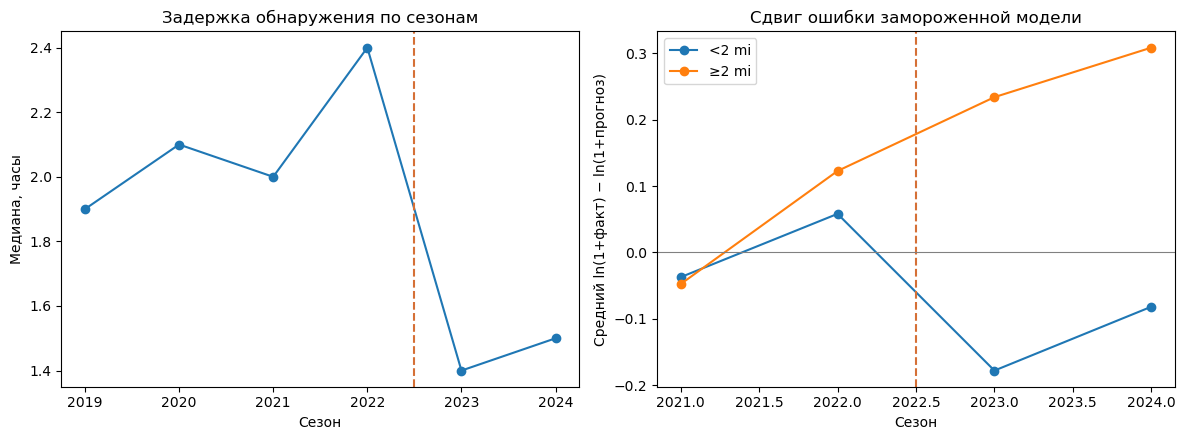

In [34]:
# Параметры этой опорной модели фиксированы независимо от поиска на 2023.
# Сравниваем ошибки одного и того же алгоритма на будущих сезонах без обновления.
STABILITY_PARAMS = {'learning_rate':0.08, 'max_depth':3, 'min_samples_leaf':20,
                    'n_estimators':200, 'random_state':RANDOM_STATE}
stability_template = make_model(GradientBoostingRegressor(**STABILITY_PARAMS))
reference_mask = df.discovery_year <= 2020
reference_model = clone(stability_template).fit(X.loc[reference_mask], y.loc[reference_mask])
future_mask = df.discovery_year >= 2021
frozen_diagnostics = df.loc[future_mask, ['discovery_year','distance_to_road_mi',TARGET]].copy()
frozen_diagnostics['predicted_acres'] = predict_acres(reference_model, X.loc[future_mask])
frozen_diagnostics['log_residual'] = np.log1p(frozen_diagnostics[TARGET])-np.log1p(frozen_diagnostics.predicted_acres)
# Здесь знак остатка факт-прогноз: положительное значение означает недооценку.
frozen_rows = []
for year, part in frozen_diagnostics.groupby('discovery_year'):
    frozen_rows.append({'year':year, 'n':len(part), 'mean_log_residual':part.log_residual.mean(),
                       **metrics(part[TARGET], part.predicted_acres)})
frozen_year_table = pd.DataFrame(frozen_rows).set_index('year')
display(frozen_year_table.round(4))
residual_break_scan = scan_season_break(frozen_diagnostics.discovery_year,
    frozen_diagnostics.log_residual, min_seasons_each_side=1)
display(residual_break_scan.round(4))

# Близость к дороге задана заранее как диагностическая граница 2 мили, не как норматив.
frozen_diagnostics['road_group'] = np.where(frozen_diagnostics.distance_to_road_mi < 2, '<2 mi', '≥2 mi')
frozen_diagnostics['period'] = np.where(frozen_diagnostics.discovery_year < 2023, '2021–2022', '2023–2024')
road_shift = frozen_diagnostics.groupby(['period','road_group']).agg(
    n=('log_residual','size'), mean_log_residual=('log_residual','mean'),
    median_acres=(TARGET,'median')).reset_index()
display(road_shift.round(4))
road_pivot = road_shift.pivot(index='road_group',columns='period',values='mean_log_residual')
near_change = road_pivot.loc['<2 mi','2023–2024']-road_pivot.loc['<2 mi','2021–2022']
far_change = road_pivot.loc['≥2 mi','2023–2024']-road_pivot.loc['≥2 mi','2021–2022']
road_difference = near_change-far_change
print(f'Сдвиг среднего остатка у дорог: {near_change:.4f}; вдали: {far_change:.4f}; '
      f'разность сдвигов: {road_difference:.4f} в масштабе log1p.')

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
axes[0].plot(season_table.index,season_table.median_delay_hours,marker='o')
axes[0].axvline(delay_break_year-.5,linestyle='--',color='#d57036')
axes[0].set(title='Задержка обнаружения по сезонам',xlabel='Сезон',ylabel='Медиана, часы')
for group, part in frozen_diagnostics.groupby('road_group'):
    yearly = part.groupby('discovery_year').log_residual.mean()
    axes[1].plot(yearly.index,yearly.values,marker='o',label=group)
axes[1].axvline(2022.5,linestyle='--',color='#d57036')
axes[1].axhline(0,color='gray',linewidth=.8)
axes[1].set(title='Сдвиг ошибки замороженной модели',xlabel='Сезон',ylabel='Средний ln(1+факт) − ln(1+прогноз)')
axes[1].legend()
fig.tight_layout()
plt.show()

Сканирование остатка и задержки измеряет разные процессы: границы могут не совпасть.
Изменение задержки согласуется с переходом на мониторинг, а различие ошибок у дорог
согласуется с изменением условий распространения. Это **интерпретация**, а не доказательство
эффекта топливных разрывов: нет карты выполненных работ, уровня тушения и контрольной группы.
Сам факт изменения наблюдаемого поля, исключённого из модели, ещё не доказывает ухудшение
прогноза. Поэтому выше отдельно приведены RMSLE, MAE и смещение одной замороженной модели.

### Проверка по сезонам и выбор обучающего окна
Сравним расширяющееся окно со скользящим окном в два сезона. Во всех этих сравнениях
используем одинаковый заранее заданный бустинг (200 деревьев, lr=0.08, depth=3),
чтобы отделить влияние окна от подбора параметров.
Внешние фолды: `2019–2020 → 2021`, `2019–2021 → 2022`, `2019–2022 → 2023`.
Для скользящего окна перед каждым контрольным сезоном остаются только два предыдущих.
Медианы и категории каждый раз учатся заново внутри Pipeline.

Случайную трёхфолдовую проверку на 2019–2023 добавляем только как иллюстрацию смешения сезонов.
Это другой состав контроля, поэтому разность метрик нельзя объявлять точным размером утечки.
Она оценивает смешанный исторический набор, а не прогноз следующего сезона.

### Что показал именно предоставленный CSV
Граница 2023 для задержки сохраняется при исключении любого из 11 штатов.
Медиана за 2019–2022 — 2,1 часа, за 2023–2024 — 1,5 часа; в соседних сезонах
2022/2023 — 2,4/1,4 часа. При этом перелом объясняет лишь 1,25% разброса
log1p задержки отдельных пожаров: существенен сдвиг процесса, а не исчезновение вариативности.

У замороженной модели средний остаток за 2021–2022 равен 0,0068, за 2023–2024 — 0,0079.
Почти нулевой общий сдвиг **скрывает различие по дорогам**: средний остаток у дорог
изменился на −0,1210, вдали от дорог — на +0,2604; разность изменений — −0,3813.
После 2023 модель в среднем переоценивает площадь возле дорог и недооценивает вдали.
По общей ошибке нельзя заключить, что после 2023 качество одинаково ухудшилось везде:
наибольший общий RMSLE замороженной модели был в 2022 (0,951), а в 2023 он равен 0,871.
Эти наблюдения требуют контроля по группам, а не автоматического удаления всех старых сезонов.


In [36]:
temporal_cv_rows = []
for validation_year in [2021,2022,2023]:
    check_mask = df.discovery_year == validation_year
    for scheme in ['expanding','rolling_2']:
        fit_mask = df.discovery_year < validation_year
        if scheme == 'rolling_2':
            fit_mask &= df.discovery_year >= validation_year-2
        assert df.loc[fit_mask,'discovery_date'].max() < df.loc[check_mask,'discovery_date'].min()
        model = clone(stability_template).fit(X.loc[fit_mask], y.loc[fit_mask])
        pred = predict_acres(model,X.loc[check_mask])
        temporal_cv_rows.append({'scheme':scheme,'validation_year':validation_year,
            'train_n':int(fit_mask.sum()),'val_n':int(check_mask.sum()),
            **metrics(y.loc[check_mask],pred)})
temporal_cv = pd.DataFrame(temporal_cv_rows)
display(temporal_cv.round(4))
temporal_summary = temporal_cv.groupby('scheme').agg(
    mean_RMSLE=('RMSLE','mean'),std_RMSLE=('RMSLE','std'),
    worst_RMSLE=('RMSLE','max'),mean_MAE_acres=('MAE_acres','mean'))
display(temporal_summary.round(4))

random_cv_rows = []
development_indices = np.flatnonzero(development_mask)
random_folds = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
for fold, (fit_positions, val_positions) in enumerate(random_folds.split(development_indices),1):
    fit_idx, val_idx = development_indices[fit_positions], development_indices[val_positions]
    model = clone(stability_template).fit(X.iloc[fit_idx],y.iloc[fit_idx])
    pred = predict_acres(model,X.iloc[val_idx])
    random_cv_rows.append({'fold':fold,'train_min_year':int(df.iloc[fit_idx].discovery_year.min()),
        'train_max_year':int(df.iloc[fit_idx].discovery_year.max()),
        'val_min_year':int(df.iloc[val_idx].discovery_year.min()),
        'val_max_year':int(df.iloc[val_idx].discovery_year.max()),
        **metrics(y.iloc[val_idx],pred)})
random_cv = pd.DataFrame(random_cv_rows)
display(random_cv.round(4))
print(f'Случайная CV: RMSLE {random_cv.RMSLE.mean():.4f} ± {random_cv.RMSLE.std():.4f}.')

# Правило выбора окна задано по доступным до 2024 числам: среднее RMSLE внешних фолдов.
chosen_window = temporal_summary.mean_RMSLE.idxmin()
print('Окно с меньшим средним RMSLE на 2021–2023:',chosen_window)
print('Разброс по трём фолдам не является доверительным интервалом.')


,scheme,validation_year,train_n,val_n,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,expanding,2021,3457,2179,0.8579,36.1185,491.2756,0.5992,0.0260,-29.0540,43.6898,19.4585
1,rolling_2,2021,3457,2179,0.8579,36.1185,491.2756,0.5992,0.0260,-29.0540,43.6898,19.4585
2,expanding,2022,5636,1432,0.9287,173.3896,2957.4244,0.5789,-0.0009,-168.5090,49.0922,24.8603
3,rolling_2,2022,4396,1432,0.9290,173.7734,2957.0075,0.5786,-0.0007,-168.7174,48.8827,24.3715
4,expanding,2023,7068,1163,0.8611,31.3767,322.3355,0.6427,0.0627,-26.0136,40.6707,18.4007
5,rolling_2,2023,3611,1163,0.8880,34.3062,326.5272,0.6200,0.0381,-25.5293,40.9286,19.0026


,mean_RMSLE,std_RMSLE,worst_RMSLE,mean_MAE_acres
scheme,,,,
expanding,0.8826,0.0400,0.9287,80.2949
rolling_2,0.8916,0.0357,0.9290,81.3994


,fold,train_min_year,train_max_year,val_min_year,val_max_year,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,1,2019,2023,2019,2023,0.8504,91.8785,2138.1585,0.6223,0.0009,-87.0179,44.2784,21.7201
1,2,2019,2023,2019,2023,0.8923,108.0809,2274.9696,0.5981,0.0021,-103.4408,46.9023,21.9023
2,3,2019,2023,2019,2023,0.8127,68.4992,2666.4505,0.6228,0.0077,-62.4778,43.0915,19.6865


Случайная CV: RMSLE 0.8518 ± 0.0398.
Окно с меньшим средним RMSLE на 2021–2023: expanding
Разброс по трём фолдам не является доверительным интервалом.


Выбираем **проверку на следующем целом сезоне**, а не случайное разбиение.
Окно обучения выше выбирается по внешним фолдам до 2024. Это предварительный выбор:
есть только один внешний сезон после перелома (2023), поэтому малое отличие окон
не доказывает устойчивое преимущество. Годам с малым числом крупных пожаров нельзя
доверять только по средней MAE.

Для подбора early stopping в каждом внешнем фолде применяем вложенную временную схему:
из доступного прошлого выделяем последний сезон для остановки, выбираем число деревьев,
затем обучаемся на всём доступном прошлом и оцениваем внешний следующий сезон.
Следующая ячейка проверяет такую схему при фиксированных lr/depth без просмотра внешней цели.
Полная вложенная сетка всех параметров потребовала бы повторять поиск внутри каждого фолда.

В выполненном сравнении средний RMSLE расширяющегося окна — 0,8826, двухсезонного —
0,8916. Разница 0,009 невелика; предварительно сохраняем накопленную историю и проверяем
каждый следующий сезон отдельно. Таблица вложенной остановки условна этому выбранному
окну: окно выбрано по тем же внешним сезонам, поэтому это разведочная оценка, а не новая
независимая проверка. Для окончательного сравнения схем нужен ещё один будущий сезон, чтоб быть увереным в прогнозах

In [37]:
nested_stop_rows = []
for outer_year in [2021,2022,2023]:
    available = df.discovery_year < outer_year
    if chosen_window == 'rolling_2':
        available &= df.discovery_year >= outer_year-2
    inner_stop = available & (df.discovery_year == outer_year-1)
    inner_fit = available & (df.discovery_year < outer_year-1)
    outer_check = df.discovery_year == outer_year
    # Фиксированные lr/depth обеспечивают независимость от поиска по внешнему 2023.
    stop_result = fit_boost_with_time_stop(X.loc[inner_fit], y.loc[inner_fit],
        X.loc[inner_stop], y.loc[inner_stop], learning_rate=.08, max_depth=3)
    model = make_model(GradientBoostingRegressor(
        **{**STABILITY_PARAMS,'n_estimators':stop_result['best_trees']}))
    model.fit(X.loc[available],y.loc[available])
    pred = predict_acres(model,X.loc[outer_check])
    nested_stop_rows.append({'outer_year':outer_year, 'inner_stop_year':outer_year-1,
        'best_trees':stop_result['best_trees'], 'inner_RMSLE':stop_result['best_RMSLE'],
        **metrics(y.loc[outer_check],pred)})
nested_stop_cv = pd.DataFrame(nested_stop_rows)
display(nested_stop_cv.round(4))
print('Внешний RMSLE вложенного early stopping:',round(nested_stop_cv.RMSLE.mean(),4))

# Окно выбрано до этой проверки; 2024 не используется, чтобы поменять решение.
window_audit_rows = []
for scheme in ['expanding','rolling_2','post_2023_only']:
    fit_mask = development_mask.copy()
    if scheme == 'rolling_2':
        fit_mask &= df.discovery_year >= 2022
    elif scheme == 'post_2023_only':
        fit_mask &= df.discovery_year >= 2023
    model = clone(stability_template).fit(X.loc[fit_mask],y.loc[fit_mask])
    pred = predict_acres(model,X_test)
    window_audit_rows.append({'scheme':scheme,'train_n':int(fit_mask.sum()),
                             **metrics(y_test,pred)})
window_audit_2024 = pd.DataFrame(window_audit_rows).set_index('scheme')
display(window_audit_2024.round(4))
print('2024 — аудит выбранной схемы, не основание переключаться на выигравшее окно.')
print('Обучение только после 2023 проверено диагностически: один сезон — мало данных для хвоста.')

,outer_year,inner_stop_year,best_trees,inner_RMSLE,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
0,2021,2020,150,0.8763,0.8581,36.1099,491.6767,0.5991,0.0244,-29.6217,43.6439,19.0913
1,2022,2021,150,0.8581,0.9317,173.6450,2957.6118,0.5762,-0.0011,-168.9737,48.5335,24.5112
2,2023,2022,200,0.9287,0.8611,31.3767,322.3355,0.6427,0.0627,-26.0136,40.6707,18.4007


Внешний RMSLE вложенного early stopping: 0.8836


,train_n,RMSLE,MAE_acres,RMSE_acres,R2_log,R2_acres,bias_acres,underestimate_pct,under_by_2x_pct
scheme,,,,,,,,,
expanding,8231,0.8464,72.6448,1272.5008,0.6448,0.0061,-67.6553,47.5975,22.3855
rolling_2,2595,0.8628,72.9233,1273.9106,0.6309,0.0039,-68.6951,46.6930,22.7812
post_2023_only,1163,0.8697,74.0571,1275.0340,0.6249,0.0021,-69.2160,50.3109,26.7948


2024 — аудит выбранной схемы, не основание переключаться на выигравшее окно.
Обучение только после 2023 проверено диагностически: один сезон — мало данных для хвоста.


## 7. Важность признаков: два способа и расхождения
Оба способа применяем **к одному настроенному бустингу**, обученному на 2019–2022:

**MDI (уменьшение неоднородности)** — встроенная `feature_importances_`, суммирующая
улучшение критерия при разбиениях деревьев на обучении. Складываем важность one-hot
столбцов и индикаторов пропусков обратно в исходные признаки.

**Permutation importance** — рост RMSLE на сезоне 2023 после перемешивания целого исходного
столбца; 10 повторений. Это измеряет потерю качества на контрольном сезоне, включая
воздействие на кодирование и индикаторы пропусков. Сезон 2023 использован при настройке,
поэтому это не независимая проверка объяснения; на 2024 отдельно сравним устойчивость рангов.

MDI нормирован до суммы 1, permutation выражен в единицах RMSLE. Сравнивать их высоты
как одинаковые проценты нельзя: сопоставляем ранги и устойчивость.


,MDI,permutation_RMSLE_increase,permutation_std,MDI_rank,permutation_rank,rank_difference
feature,,,,,,
distance_to_road_mi,0.2996,0.3954,0.0135,1.0,1.0,0.0
wind_speed_mph,0.2573,0.3203,0.0144,2.0,2.0,0.0
slope_deg,0.0864,0.0976,0.0109,4.0,3.0,1.0
energy_release_component,0.1295,0.0918,0.0073,3.0,4.0,-1.0
distance_to_town_mi,0.0342,0.0467,0.0039,7.0,5.0,2.0
fuel_model,0.0172,0.0257,0.0052,8.0,6.0,2.0
fuel_moisture_pct,0.0705,0.0195,0.0087,5.0,7.0,-2.0
relative_humidity_pct,0.0414,0.0143,0.0070,6.0,8.0,-2.0
state,0.0070,0.0080,0.0021,13.0,9.0,4.0


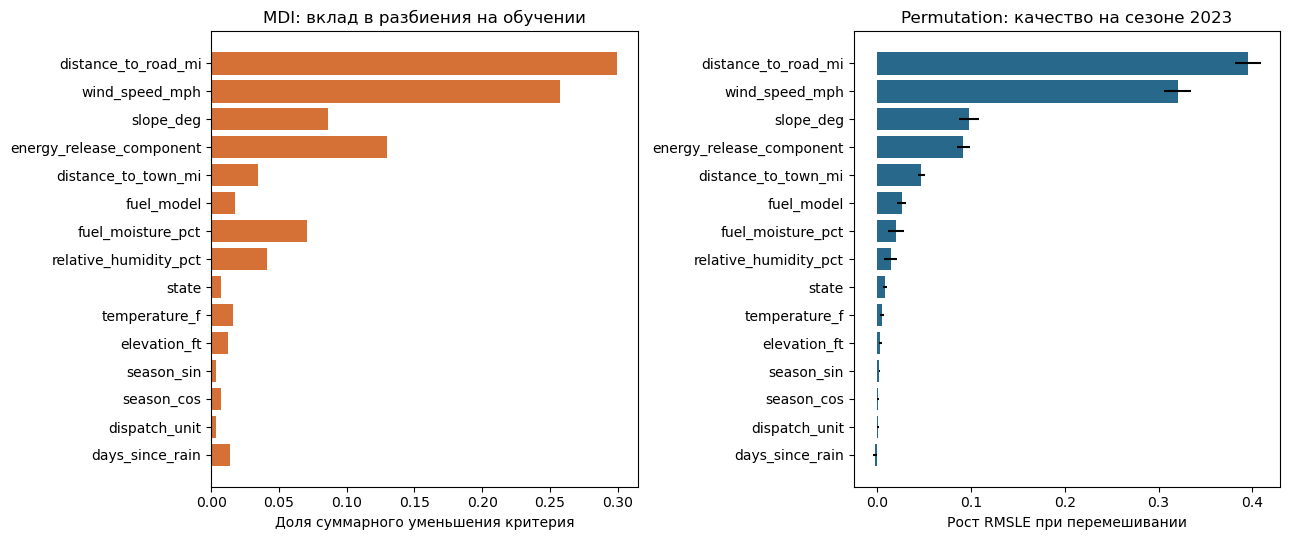

Наибольшие различия рангов:


,MDI,permutation_RMSLE_increase,permutation_std,MDI_rank,permutation_rank,rank_difference
feature,,,,,,
days_since_rain,0.0140,-0.0023,0.0023,10.0,15.0,-5.0
state,0.0070,0.0080,0.0021,13.0,9.0,4.0
distance_to_town_mi,0.0342,0.0467,0.0039,7.0,5.0,2.0
fuel_model,0.0172,0.0257,0.0052,8.0,6.0,2.0
fuel_moisture_pct,0.0705,0.0195,0.0087,5.0,7.0,-2.0


In [38]:
# создаём бустинговую модель
boost_pipeline = boost_train.regressor_
encoded_names = boost_pipeline.named_steps['prep'].get_feature_names_out()
encoded_mdi = boost_pipeline.named_steps['model'].feature_importances_

def original_feature(encoded_name):
    name = encoded_name.split('__',1)[1]
    if name.startswith('missingindicator_'):
        return name.removeprefix('missingindicator_')
    if name in numeric_features:
        return name
    for feature in sorted(categorical_features,key=len,reverse=True):
        if name.startswith(feature+'_'):
            return feature
    raise ValueError(f'Не удалось сопоставить столбец {encoded_name}')

mdi_parts = pd.DataFrame({'encoded_feature':encoded_names,'MDI':encoded_mdi})
mdi_parts['feature'] = mdi_parts.encoded_feature.map(original_feature)
mdi = mdi_parts.groupby('feature').MDI.sum().reindex(FEATURES,fill_value=0)
assert abs(mdi.sum()-1) < 1e-8
boost_perm_2023 = permutation_importance(boost_train,X_val,y_val,scoring=neg_rmsle,
    n_repeats=10,random_state=RANDOM_STATE,n_jobs=1)
importance_two_methods = pd.DataFrame({'feature':FEATURES,'MDI':mdi.to_numpy(),
    'permutation_RMSLE_increase':boost_perm_2023.importances_mean,
    'permutation_std':boost_perm_2023.importances_std}).set_index('feature')
importance_two_methods['MDI_rank'] = importance_two_methods.MDI.rank(ascending=False,method='min')
importance_two_methods['permutation_rank'] = importance_two_methods.permutation_RMSLE_increase.rank(ascending=False,method='min')
importance_two_methods['rank_difference'] = importance_two_methods.MDI_rank-importance_two_methods.permutation_rank
importance_two_methods = importance_two_methods.sort_values('permutation_rank')
display(importance_two_methods.round(4))

fig, axes = plt.subplots(1,2,figsize=(13,5.5))
order = importance_two_methods.index[::-1]
axes[0].barh(order,importance_two_methods.loc[order,'MDI'],color='#d57036')
axes[0].set(title='MDI: вклад в разбиения на обучении',xlabel='Доля суммарного уменьшения критерия')
axes[1].barh(order,importance_two_methods.loc[order,'permutation_RMSLE_increase'],
    xerr=importance_two_methods.loc[order,'permutation_std'],color='#28688b')
axes[1].set(title='Permutation: качество на сезоне 2023',xlabel='Рост RMSLE при перемешивании')
fig.tight_layout()
plt.show()
print('Наибольшие различия рангов:')
display(importance_two_methods.reindex(
    importance_two_methods.rank_difference.abs().sort_values(ascending=False).index).head(5).round(4))

In [39]:
# Проверяем совместную полезность связанных полей, которые могут заменять друг друга.
# Внутри группы строки переставляются вместе: связи между её столбцами сохраняются.
related_groups = {
    'география: state + dispatch_unit':['state','dispatch_unit'],
    'сухость: fuel_moisture + rain + RH + ERC':
        ['fuel_moisture_pct','days_since_rain','relative_humidity_pct','energy_release_component'],
    'сезонность: sin + cos':['season_sin','season_cos']}
base_rmsle = metrics(y_val,predict_acres(boost_train,X_val))['RMSLE']
rng = np.random.default_rng(RANDOM_STATE)
group_rows = []
for name, group in related_groups.items():
    losses = []
    for repeat in range(10):
        shuffled = X_val.copy()
        shuffled[group] = X_val.iloc[rng.permutation(len(X_val))][group].to_numpy()
        losses.append(metrics(y_val,predict_acres(boost_train,shuffled))['RMSLE']-base_rmsle)
    group_rows.append({'group':name,'joint_RMSLE_increase':np.mean(losses),
                      'std':np.std(losses),
                      'sum_individual_increases':importance_two_methods.loc[group,'permutation_RMSLE_increase'].sum()})
grouped_importance = pd.DataFrame(group_rows)
display(grouped_importance.round(4))

# Та же замороженная модель и тот же метод, меняется только сезон проверки.
boost_perm_2024 = permutation_importance(boost_train,X_test,y_test,scoring=neg_rmsle,
    n_repeats=5,random_state=RANDOM_STATE,n_jobs=1)
importance_over_time = importance_two_methods[['permutation_RMSLE_increase','permutation_rank']].rename(
    columns={'permutation_RMSLE_increase':'increase_2023','permutation_rank':'rank_2023'})
importance_over_time['increase_2024'] = pd.Series(boost_perm_2024.importances_mean,index=FEATURES)
importance_over_time['rank_2024'] = importance_over_time.increase_2024.rank(ascending=False,method='min')
display(importance_over_time.sort_values('rank_2024').round(4))
rank_correlation = importance_two_methods[['MDI','permutation_RMSLE_increase']].corr(method='spearman').iloc[0,1]
print('Spearman между MDI и permutation на 2023:',round(rank_correlation,3))


,group,joint_RMSLE_increase,std,sum_individual_increases
0,география: state + dispatch_unit,0.0108,0.0026,0.0086
1,сухость: fuel_moisture + rain + RH + ERC,0.2075,0.0075,0.1232
2,сезонность: sin + cos,0.0021,0.0013,0.0028


,increase_2023,rank_2023,increase_2024,rank_2024
feature,,,,
distance_to_road_mi,0.3954,1.0,0.3822,1.0
wind_speed_mph,0.3203,2.0,0.3109,2.0
energy_release_component,0.0918,4.0,0.0881,3.0
slope_deg,0.0976,3.0,0.0877,4.0
fuel_moisture_pct,0.0195,7.0,0.0394,5.0
distance_to_town_mi,0.0467,5.0,0.0376,6.0
fuel_model,0.0257,6.0,0.0273,7.0
relative_humidity_pct,0.0143,8.0,0.0234,8.0
state,0.0080,9.0,0.0099,9.0


Spearman между MDI и permutation на 2023: 0.882


### Почему появляются различия
MDI использует обучающие разбиения и склонен отдавать больше веса признакам с большим
числом возможных порогов/категорий. Поэтому высокое место подразделения в MDI при
низкой permutation-важности может означать подгонку локальных особенностей.
Эту возможность проверяем числами, а не объявляем заранее установленным фактом.

Permutation оценивает перенос на другой сезон. Связанный признак может заменяться другим:
штат — подразделением, влажность топлива — ERC/влажностью воздуха. Совместное перемешивание
показывает, насколько группа полезна в целом; его эффект не обязан равняться сумме отдельных.
Обычное перемешивание также создаёт редкие сочетания признаков, поэтому не даёт причинной оценки.
Различия могут отражать переобучение, связь признаков, смену сезона и случайность перемешиваний.
Направление влияния и эффект изменения одного фактора ни MDI, ни permutation не определяют.

### Конкретные расхождения в этой работе
Оба метода ставят расстояние до дороги и ветер на первые два места. ERC и уклон меняются
местами (3/4 и 4/3), то есть основные факторы устойчивы к способу оценки.

Число дней без дождя находится на 10-м месте по MDI (1,40% суммарного вклада в разбиения),
но на 15-м по permutation: изменение RMSLE −0,0023 при разбросе 0,0023.
Это показывает использование признака на обучении без устойчивой индивидуальной пользы
на 2023. Возможные объяснения — связь с другими показателями сухости и подгонка;
по одному этому числу удалять признак не решаем.
Влажность топлива тоже опускается с 5-го места по MDI на 7-е по permutation.
Совместное перемешивание влажности топлива, дней без дождя, влажности воздуха и ERC
увеличивает RMSLE на 0,2075, тогда как сумма индивидуальных увеличений — 0,1232.
Это согласуется с тем, что связанные показатели частично заменяют друг друга.

Штат, наоборот, поднимается с 13-го на 9-е место. Подразделение остаётся почти бесполезным
по обоим методам (15-е и 14-е места): в этих результатах нет оснований утверждать,
что именно большая кардинальность подразделения завысила его важность.
Приведённые числа относятся к выполненному расчёту на исходном CSV; 

In [40]:
print('Итоги по бустинговым моделям:')
print(f'Бустинг: learning_rate={boost_params["learning_rate"]}, depth={boost_params["max_depth"]}, '
      f'число деревьев={boost_params["n_estimators"]}.')
print('Модель выбрана по сезону 2023:',expanded_best_name)
chosen_test = expanded_test.loc[expanded_best_name]
print(f'Историческая проверка 2024: RMSLE={chosen_test.RMSLE:.3f}, '
      f'MAE={chosen_test.MAE_acres:.2f} акра, R² в акрах={chosen_test.R2_acres:.3f}.')
print(f'Бустинг/лес по времени полного fit в один поток: '
      f'{quality_time.loc["Градиентный бустинг","fit_time_vs_forest"]:.2f} раза; поиск параметров оплачивается отдельно.')
print(f'Перелом задержки обнаружения: {delay_break_year}; '
      f'граница по остаткам замороженной модели: {int(residual_break_scan.iloc[0].break_year)}.')
print(f'Доля снижения SSE при переломе задержки: {delay_break_scan.iloc[0].SSE_reduction_pct:.2f}%; '
      'даже устойчивый сдвиг среднего может объяснять малую часть разброса отдельных событий.')
print('Выбранная проверка: внешние целые сезоны с вложенной остановкой на последнем прошлом сезоне.')
print('Предварительное окно обучения:',chosen_window)
print('Два метода важности согласуются прежде всего по:',
      ', '.join(importance_two_methods.head(3).index))
print('MDI и permutation измеряют разные величины; таблица различий рангов и групповые перестановки объясняют расхождения.')
print(f'Недооценка более чем вдвое для пожаров от 1000 акров у выбранной модели: '
      f'{expanded_tail.loc[expanded_best_name,"large_under_by_2x_pct"]:.1f}% '
      f'из {int(expanded_tail.loc[expanded_best_name,"n_large"])} случаев.')
print('Обновление: пересмотр перед сезоном и ежемесячный контроль завершённых событий; '
      'оптимальный календарный интервал пока не установлен.')
print('При смене мониторинга/топливных карт требуется досрочная проверка и переобучение. '
      'Для независимой оценки следующих изменений нужен новый сезон, не использованный в этих сравнениях.')

Итоги по бустинговым моделям:
Бустинг: learning_rate=0.08, depth=5, число деревьев=130.
Модель выбрана по сезону 2023: Градиентный бустинг
Историческая проверка 2024: RMSLE=0.849, MAE=73.93 акра, R² в акрах=0.006.
Бустинг/лес по времени полного fit в один поток: 0.29 раза; поиск параметров оплачивается отдельно.
Перелом задержки обнаружения: 2023; граница по остаткам замороженной модели: 2022.
Доля снижения SSE при переломе задержки: 1.25%; даже устойчивый сдвиг среднего может объяснять малую часть разброса отдельных событий.
Выбранная проверка: внешние целые сезоны с вложенной остановкой на последнем прошлом сезоне.
Предварительное окно обучения: expanding
Два метода важности согласуются прежде всего по: distance_to_road_mi, wind_speed_mph, slope_deg
MDI и permutation измеряют разные величины; таблица различий рангов и групповые перестановки объясняют расхождения.
Недооценка более чем вдвое для пожаров от 1000 акров у выбранной модели: 100.0% из 13 случаев.
Обновление: пересмотр перед

## 8. Частичная зависимость двух ключевых признаков
Объясняем **финальную выбранную модель**, обученную на 2019–2023, с уже зафиксированными
параметрами. Два признака выбираем по permutation importance на 2023: расстояние до дороги
и скорость ветра. По 2024 для этого выбора параметры не меняем.

PDP показывает средний прогноз, если всем пожарам в фоновой выборке задать одно значение
признака, оставив остальные данные каждого события прежними. Усредняем по 2000 случайно
выбранным событиям из обучения 2019–2023; по топливу отдельно усредняем соответствующие группы.
Диапазон сетки — 1–99-й процентили обучения: избегаем вывода далеко вне наблюдавшихся условий.

Основные графики показывают **средний предсказанный размер в акрах**.
Дополнительные центрированные ICE-кривые показывают, насколько форма отличается для отдельных
пожаров, в масштабе log1p. Центрирование вычитает значение первой точки каждой кривой.
Деревья дают ступенчатую зависимость; локальный скачок — особенность модели, не универсальный
физический порог и не норматив отправки расчётов.

PDP не доказывает причинное влияние: при замене одного признака могут появиться необычные
сочетания с другими (например, расстояний и территории). Различие кривых по топливу
описывает прогноз модели и состав групп, а не изолированный эксперимент.

### Форма зависимостей в выполненном расчёте
Увеличение ветра даёт ступенчатый рост среднего прогноза: при 13 и 14 милях/ч PDP равен
14,46 и 18,82 акра, при 20 и 25 милях/ч — 33,62 и 99,79 акра. Форма усиливается
на больших скоростях. Рядом с 25 милями/ч в обучении всего 16 событий, поэтому хвост
кривой требует особого внимания. Скорость в CSV округлена до целых: отсутствие строк
в интервале между 25,04 и 25,52 не означает отсутствие наблюдений по обе стороны
порога дерева; для поддержки смотрите соседние значения и таблицу окрестностей.

С удалением от дороги прогноз в целом растёт: PDP при 1 миле — 7,62 акра, при 3 милях —
16,07 акра. Есть локальный пик около 5,8 мили и последующий спад: это немонотонный участок
обученной зависимости, а не доказательство особого физического порога. Две из 50 ступеней
сетки уменьшают прогноз. У conifer forest и shrub/chaparral прогноз на графике выше,
чем у hardwood forest; это модельное сравнение групп с разным составом остальных условий.

,grid_min,grid_max,mean_prediction_at_min_acres,mean_prediction_at_max_acres,largest_increase_from,largest_increase_to,largest_increase_acres,training_in_largest_step_n,share_non_decreasing_steps
feature,,,,,,,,,
distance_to_road_mi,0.13,9.191,4.4626,44.8804,5.7478,5.929,8.3996,34,0.96
wind_speed_mph,2.00,26.000,4.1430,136.9207,25.0400,25.520,37.1293,0,1.00


,feature,value,PDP_mean_acres,training_in_neighborhood_n,neighborhood_radius
0,distance_to_road_mi,0.5,5.8498,2157,0.25
1,distance_to_road_mi,1.0,7.6240,1510,0.25
2,distance_to_road_mi,2.0,11.2012,824,0.25
3,distance_to_road_mi,2.2,12.0467,706,0.25
4,distance_to_road_mi,3.0,16.0722,474,0.25
5,distance_to_road_mi,6.0,45.9586,87,0.25
6,wind_speed_mph,5.0,5.6005,807,0.50
7,wind_speed_mph,10.0,10.3522,564,0.50
8,wind_speed_mph,13.0,14.4554,301,0.50
9,wind_speed_mph,14.0,18.8185,238,0.50


Количество реальных наблюдений рядом с точкой показывает поддержку данных, но не является доверительным интервалом PDP.


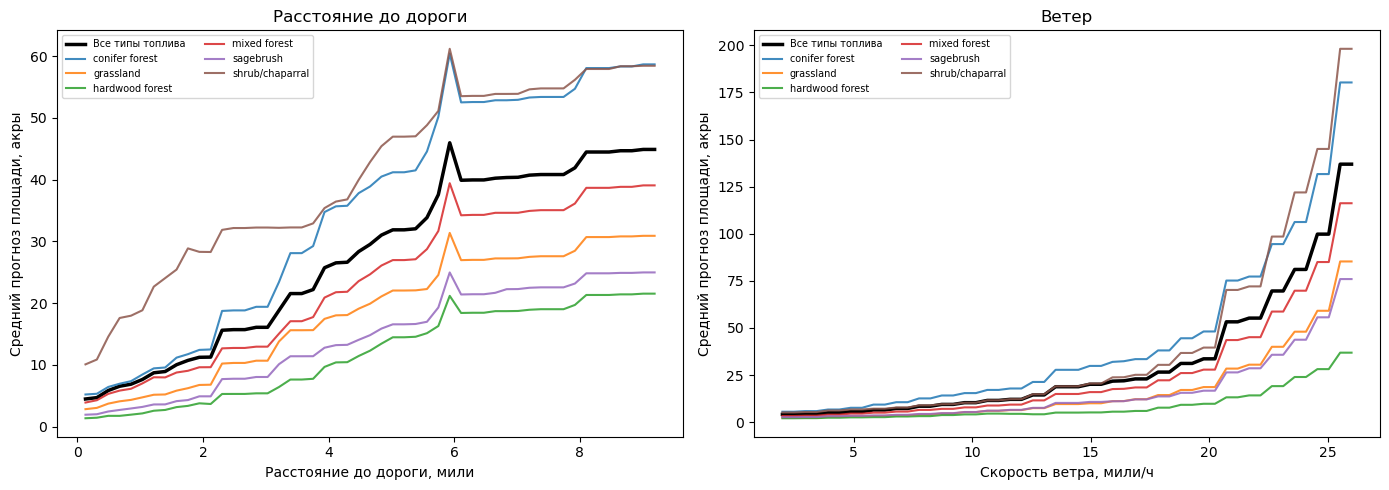

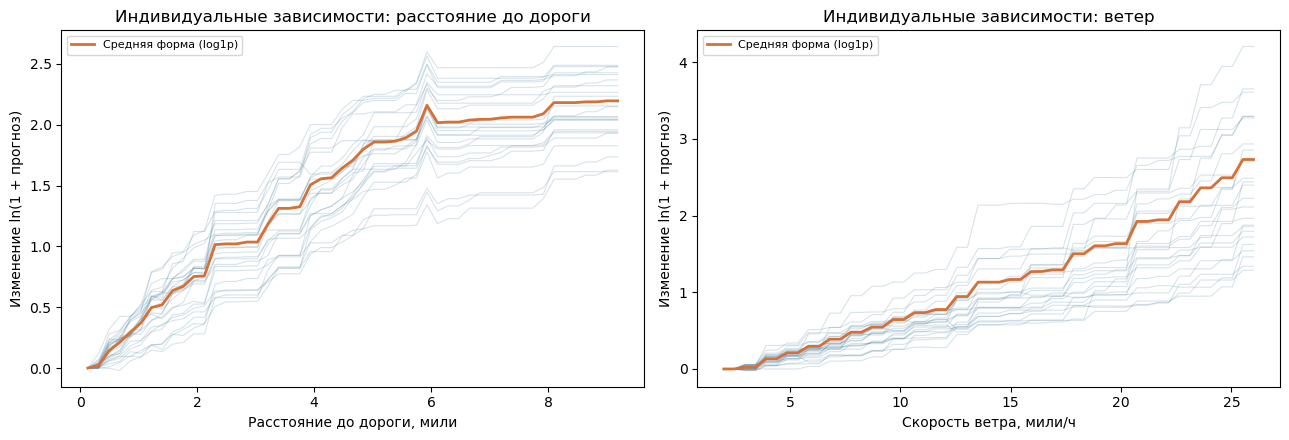

Расстояние до дороги: крупнейший рост на сетке между 5.75 и 5.93; прирост среднего прогноза 8.40 акра.
Ветер: крупнейший рост на сетке между 25.04 и 25.52; прирост среднего прогноза 37.13 акра.
expm1 среднего log-прогноза не подменяет средний прогноз в акрах: обе величины считаются раздельно.


In [41]:
report_model = expanded_final_models[expanded_best_name]
key_features = importance_two_methods.sort_values('permutation_rank').head(2).index.tolist()
assert key_features == ['distance_to_road_mi','wind_speed_mph']
feature_labels = {'distance_to_road_mi':'Расстояние до дороги, мили',
                  'wind_speed_mph':'Скорость ветра, мили/ч'}
feature_names_ru = {
    'distance_to_road_mi':'Расстояние до дороги', 'wind_speed_mph':'Ветер',
    'energy_release_component':'ERC', 'slope_deg':'Уклон',
    'distance_to_town_mi':'Расстояние до города', 'fuel_model':'Тип топлива',
    'fuel_moisture_pct':'Влажность топлива', 'relative_humidity_pct':'Влажность воздуха',
    'temperature_f':'Температура', 'days_since_rain':'Дни без дождя',
    'state':'Штат', 'dispatch_unit':'Подразделение', 'elevation_ft':'Высота',
    'season_sin':'Сезонность: sin', 'season_cos':'Сезонность: cos'}

def explain_log_prediction(frame):
    # Объясняем именно применяемый прогноз, включая ограничение площади снизу нулём.
    return np.log1p(predict_acres(report_model,frame))

pdp_background = X_development.sample(n=min(2000,len(X_development)),random_state=RANDOM_STATE)
ice_positions = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(pdp_background),
    size=min(25,len(pdp_background)),replace=False))
pdp_results, pdp_shape_rows = {}, []
pdp_anchor_rows = []
for feature in key_features:
    lower,upper = X_development[feature].quantile([.01,.99])
    grid = np.linspace(lower,upper,51)
    acres_curves, log_curves = [], []
    for value in grid:
        changed = pdp_background.copy()
        changed[feature] = value  # Меняем только исследуемый исходный столбец.
        pred = predict_acres(report_model,changed)
        acres_curves.append(pred)
        log_curves.append(np.log1p(pred))
    acres_matrix,log_matrix = np.asarray(acres_curves),np.asarray(log_curves)
    mean_acres = acres_matrix.mean(axis=1)
    increments = np.diff(mean_acres)
    strongest_step = int(np.argmax(increments))
    pdp_results[feature] = {'grid':grid,'acres':acres_matrix,'log':log_matrix}
    pdp_shape_rows.append({'feature':feature,'grid_min':grid[0],'grid_max':grid[-1],
        'mean_prediction_at_min_acres':mean_acres[0],
        'mean_prediction_at_max_acres':mean_acres[-1],
        'largest_increase_from':grid[strongest_step],
        'largest_increase_to':grid[strongest_step+1],
        'largest_increase_acres':increments[strongest_step],
        'training_in_largest_step_n':int(X_development[feature].between(
            grid[strongest_step],grid[strongest_step+1],inclusive='left').sum()),
        'share_non_decreasing_steps':np.mean(increments>=-1e-10)})
    anchors = [0.5,1,2,2.2,3,6] if feature=='distance_to_road_mi' else [5,10,13,14,20,25]
    for anchor in anchors:
        changed = pdp_background.copy()
        changed[feature] = anchor
        radius = .25 if feature=='distance_to_road_mi' else .5
        pdp_anchor_rows.append({'feature':feature,'value':anchor,
            'PDP_mean_acres':predict_acres(report_model,changed).mean(),
            'training_in_neighborhood_n':int(X_development[feature].between(anchor-radius,anchor+radius).sum()),
            'neighborhood_radius':radius})
pdp_shape_table = pd.DataFrame(pdp_shape_rows).set_index('feature')
display(pdp_shape_table.round(4))
display(pd.DataFrame(pdp_anchor_rows).round(4))
print('Количество реальных наблюдений рядом с точкой показывает поддержку данных, '
      'но не является доверительным интервалом PDP.')

fig,axes = plt.subplots(1,2,figsize=(14,5))
for ax,feature in zip(axes,key_features):
    result = pdp_results[feature]
    ax.plot(result['grid'],result['acres'].mean(axis=1),color='black',linewidth=2.5,label='Все типы топлива')
    for fuel in sorted(pdp_background.fuel_model.unique()):
        fuel_mask = (pdp_background.fuel_model==fuel).to_numpy()
        ax.plot(result['grid'],result['acres'][:,fuel_mask].mean(axis=1),label=fuel,alpha=.85)
    ax.set(title=feature_names_ru[feature],xlabel=feature_labels[feature],
           ylabel='Средний прогноз площади, акры')
    ax.legend(fontsize=7,ncol=2)
fig.tight_layout()
plt.show()

fig,axes = plt.subplots(1,2,figsize=(13,4.5))
for ax,feature in zip(axes,key_features):
    result = pdp_results[feature]
    ice = result['log'][:,ice_positions]
    ax.plot(result['grid'],ice-ice[0,:],color='#28688b',alpha=.18,linewidth=.8)
    centered_pdp = result['log'].mean(axis=1)-result['log'][0,:].mean()
    ax.plot(result['grid'],centered_pdp,color='#d57036',linewidth=2,label='Средняя форма (log1p)')
    ax.set(title='Индивидуальные зависимости: '+feature_names_ru[feature].lower(),
           xlabel=feature_labels[feature],ylabel='Изменение ln(1 + прогноз)')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for feature in key_features:
    row = pdp_shape_table.loc[feature]
    print(f'{feature_names_ru[feature]}: крупнейший рост на сетке между '
          f'{row.largest_increase_from:.2f} и {row.largest_increase_to:.2f}; '
          f'прирост среднего прогноза {row.largest_increase_acres:.2f} акра.')
print('expm1 среднего log-прогноза не подменяет средний прогноз в акрах: обе величины считаются раздельно.')

## 9. Разбор трёх отдельных пожаров через SHAP
Три случая выбираем из исторической проверки 2024 по правилу, зафиксированному до объяснения:
- **типичный по площади** — ближайший к медиане площади 2024, при равенстве по ID;
- **крупный** — наибольший пожар от 1000 акров, кроме уже выбранного худшего случая;
- **самая большая ошибка** — максимальная абсолютная ошибка в акрах.

«Типичный» относится к площади, не ко всем погодным условиям. Крупный и худший случаи
должны быть разными событиями. Фактическую площадь используем для выбора и оценки,
но она не становится входом модели или объяснителя.

Используем **permutation SHAP**, то есть приближённые значения Шепли через полные случайные
порядки включения признаков и обратные порядки. Реализация ниже использует numpy/pandas
и не требует установленного пакета `shap`; это самостоятельная реализация перестановочного
алгоритма SHAP, а не вызов `TreeExplainer` и не глобальная permutation importance из пункта 7.

Для коалиции S считаем `v(S) = mean_b f(x_S, b_остальные)`: значения исключённых признаков
берём из 64 фоновых строк обучения 2019–2023. Функция f возвращает `ln(1 + прогноз в акрах)`.
Каждый исходный столбец — один игрок; категории кодируются в Pipeline после подстановки,
поэтому невозможные комбинации one-hot внутри одной категории не создаются.

\[ f(x) = E_b[f(b)] + \sum_j \phi_j(x) \]

Знак φ показывает увеличение/уменьшение **прогноза модели** относительно фона.
Вклады выражены в log1p, их нельзя складывать с площадью в акрах.
Аддитивность проверяем численно. Отдельно проверяем сходимость по 32/64/128 парам порядков
и приводим стандартную ошибку Монте-Карло. Она не включает неопределённость модели,
выбора 64 фоновых событий или фактической будущей площади.

Такое маскирование — интервенционное относительно эмпирического фона: оно может разорвать
связь штата/подразделения или погодных показателей. SHAP объясняет решение обученной модели,
не доказывает причинный механизм пожара и не объясняет отсутствующие в таблице обстоятельства.


In [42]:
# Классификация пожаров
case_pool = df.loc[test_mask,['fire_id','discovery_date','state','fuel_model',TARGET]].copy()
case_pool['predicted_acres'] = predict_acres(report_model,X_test)
case_pool['absolute_error_acres'] = abs(case_pool.predicted_acres-case_pool[TARGET])
worst_case = case_pool.sort_values(['absolute_error_acres','fire_id'],ascending=[False,True]).index[0]
typical_case = case_pool.assign(distance_to_median=(case_pool[TARGET]-y_test.median()).abs()).sort_values(
    ['distance_to_median','fire_id']).index[0]
large_candidates = case_pool.loc[(case_pool[TARGET]>=1000)&(case_pool.index!=worst_case)]
assert len(large_candidates)>0, 'Нет отдельного крупного события для разбора.'
large_case = large_candidates.sort_values([TARGET,'fire_id'],ascending=[False,True]).index[0]
case_indices = {'Типичный по площади':typical_case,'Крупный пожар':large_case,'Наибольшая ошибка':worst_case}
assert len(set(case_indices.values()))==3
case_summary = pd.DataFrame([
    {'case':name,**case_pool.loc[index].to_dict(),
     'log_predicted':float(explain_log_prediction(X.loc[[index]])[0]),
     'actual_to_prediction':case_pool.loc[index,TARGET]/max(case_pool.loc[index,'predicted_acres'],1e-12)}
    for name,index in case_indices.items()]).set_index('case')
display(case_summary.round(4))
print('Все входные данные трёх событий (только доступные при обнаружении):')
case_inputs = X.loc[list(case_indices.values())].copy()
case_inputs.index = list(case_indices)
display(case_inputs.T)

shap_background = X_development.sample(n=min(64,len(X_development)),random_state=RANDOM_STATE)
shap_base_value = float(explain_log_prediction(shap_background).mean())
print(f'Фон в log1p: {shap_base_value:.4f}; обратное преобразование: '
      f'{np.expm1(shap_base_value):.2f} акра. Это не средняя фактическая площадь и не средний прогноз в акрах.')

,fire_id,discovery_date,state,fuel_model,burned_area_acres,predicted_acres,absolute_error_acres,log_predicted,actual_to_prediction
case,,,,,,,,,
Типичный по площади,fire-313516,2024-07-27,montana,conifer forest,3.2,7.3296,4.1296,2.1198,0.4366
Крупный пожар,fire-456719,2024-08-22,california,shrub/chaparral,29790.0,48.3921,29741.6079,3.8998,615.5969
Наибольшая ошибка,fire-729796,2024-06-03,arizona,grassland,41130.0,112.0987,41017.9013,4.7283,366.9089


Все входные данные трёх событий (только доступные при обнаружении):


,Типичный по площади,Крупный пожар,Наибольшая ошибка
temperature_f,87.0,82.0,89.0
relative_humidity_pct,22.0,8.0,4.0
wind_speed_mph,4.0,11.0,23.0
days_since_rain,36.0,56.0,25.0
fuel_moisture_pct,NaN,4.9,8.5
energy_release_component,64,65,28
elevation_ft,5421,4797,4512
slope_deg,9.8,4.0,12.3
distance_to_road_mi,1.88,3.1,0.56
distance_to_town_mi,11.95,6.8,4.38


Фон в log1p: 1.4061; обратное преобразование: 3.08 акра. Это не средняя фактическая площадь и не средний прогноз в акрах.


In [43]:
def permutation_shap_one(row,background,prediction_function,n_pairs=128,seed=42):
    """SHAP: средние предельные вклады по случайным порядкам и их разворотам."""
    rng = np.random.default_rng(seed)
    features = list(background.columns)
    p = len(features)
    row = row.reindex(features)
    base = float(prediction_function(background).mean())
    final = float(prediction_function(pd.DataFrame([row],columns=features))[0])
    pair_contributions = []
    # Пакетируем все ступени двух порядков, чтобы не делать 32 отдельных predict на пару.
    for pair in range(n_pairs):
        order = rng.permutation(p)
        all_states = []
        for direction in [order,order[::-1]]:
            current = background.copy()
            all_states.append(current.copy())
            for position in direction:
                current[features[position]] = row[features[position]]
                all_states.append(current.copy())
        batched = pd.concat(all_states,ignore_index=True)
        values = prediction_function(batched).reshape(2,p+1,len(background)).mean(axis=2)
        pair_phi = np.zeros(p)
        for direction_number,direction in enumerate([order,order[::-1]]):
            increments = np.diff(values[direction_number])
            pair_phi[direction] += increments/2
        # Полный путь телескопируется: сумма вкладов всегда даёт разность прогноз-фон.
        assert abs(pair_phi.sum()-(final-base)) < 1e-9
        pair_contributions.append(pair_phi)
    pair_contributions = np.asarray(pair_contributions)
    phi = pair_contributions.mean(axis=0)
    se = pair_contributions.std(axis=0,ddof=1)/np.sqrt(n_pairs)
    return {'base_value':base,'prediction':final,'phi':phi,'standard_error':se,
            'pair_contributions':pair_contributions,'features':features}

shap_results,shap_convergence_rows,shap_additivity_rows = {},[],[]
for name,index in case_indices.items():
    result = permutation_shap_one(X.loc[index],shap_background,explain_log_prediction,
                                  n_pairs=128,seed=RANDOM_STATE)
    shap_results[name] = result
    for pairs in [32,64,128]:
        estimate = result['pair_contributions'][:pairs].mean(axis=0)
        se = result['pair_contributions'][:pairs].std(axis=0,ddof=1)/np.sqrt(pairs)
        shap_convergence_rows.append({'case':name,'pairs':pairs,'total_permutations':2*pairs,
            'max_abs_difference_from_128_pairs':abs(estimate-result['phi']).max(),
            'max_MC_standard_error':se.max()})
    rebuilt = result['base_value']+result['phi'].sum()
    shap_additivity_rows.append({'case':name,'base_value':result['base_value'],
        'sum_SHAP':result['phi'].sum(),'reconstructed_log_prediction':rebuilt,
        'model_log_prediction':result['prediction'],'absolute_additivity_error':abs(rebuilt-result['prediction']),
        'reconstructed_acres':np.expm1(rebuilt)})
shap_convergence = pd.DataFrame(shap_convergence_rows)
shap_additivity = pd.DataFrame(shap_additivity_rows).set_index('case')
display(shap_convergence.round(6))
display(shap_additivity.round(8))
assert shap_additivity.absolute_additivity_error.max()<1e-9
print('Аддитивность проверена. Она не доказывает точность отдельных вкладов; для них приведена сходимость.')

# Дополнительная проверка реализации на линейной функции с известными точными значениями Шепли.
test_background = pd.DataFrame({'a':[0.,1.,2.], 'b':[3.,4.,5.], 'c':[1.,2.,3.]})
test_row = pd.Series({'a':2.,'b':1.,'c':4.})
coefficients = np.array([2.,-3.,.5])
def linear_test_function(frame):
    return frame.to_numpy()@coefficients+7
linear_check = permutation_shap_one(test_row,test_background,linear_test_function,n_pairs=4,seed=42)
known_phi = coefficients*(test_row.to_numpy()-test_background.mean().to_numpy())
assert np.allclose(linear_check['phi'],known_phi,atol=1e-10)
print('Самостоятельная реализация SHAP также проверена на аналитически известном линейном примере.')

,case,pairs,total_permutations,max_abs_difference_from_128_pairs,max_MC_standard_error
0,Типичный по площади,32,64,0.001333,0.001353
1,Типичный по площади,64,128,0.001086,0.000921
2,Типичный по площади,128,256,0.000000,0.000668
3,Крупный пожар,32,64,0.005171,0.009022
4,Крупный пожар,64,128,0.005225,0.005983
5,Крупный пожар,128,256,0.000000,0.004555
6,Наибольшая ошибка,32,64,0.006644,0.012817
7,Наибольшая ошибка,64,128,0.005648,0.009965
8,Наибольшая ошибка,128,256,0.000000,0.006850


,base_value,sum_SHAP,reconstructed_log_prediction,model_log_prediction,absolute_additivity_error,reconstructed_acres
case,,,,,,
Типичный по площади,1.406077,0.713736,2.119813,2.119813,0.0,7.329579
Крупный пожар,1.406077,2.493712,3.899790,3.899790,0.0,48.392056
Наибольшая ошибка,1.406077,3.322183,4.728261,4.728261,0.0,112.098667


Аддитивность проверена. Она не доказывает точность отдельных вкладов; для них приведена сходимость.
Самостоятельная реализация SHAP также проверена на аналитически известном линейном примере.


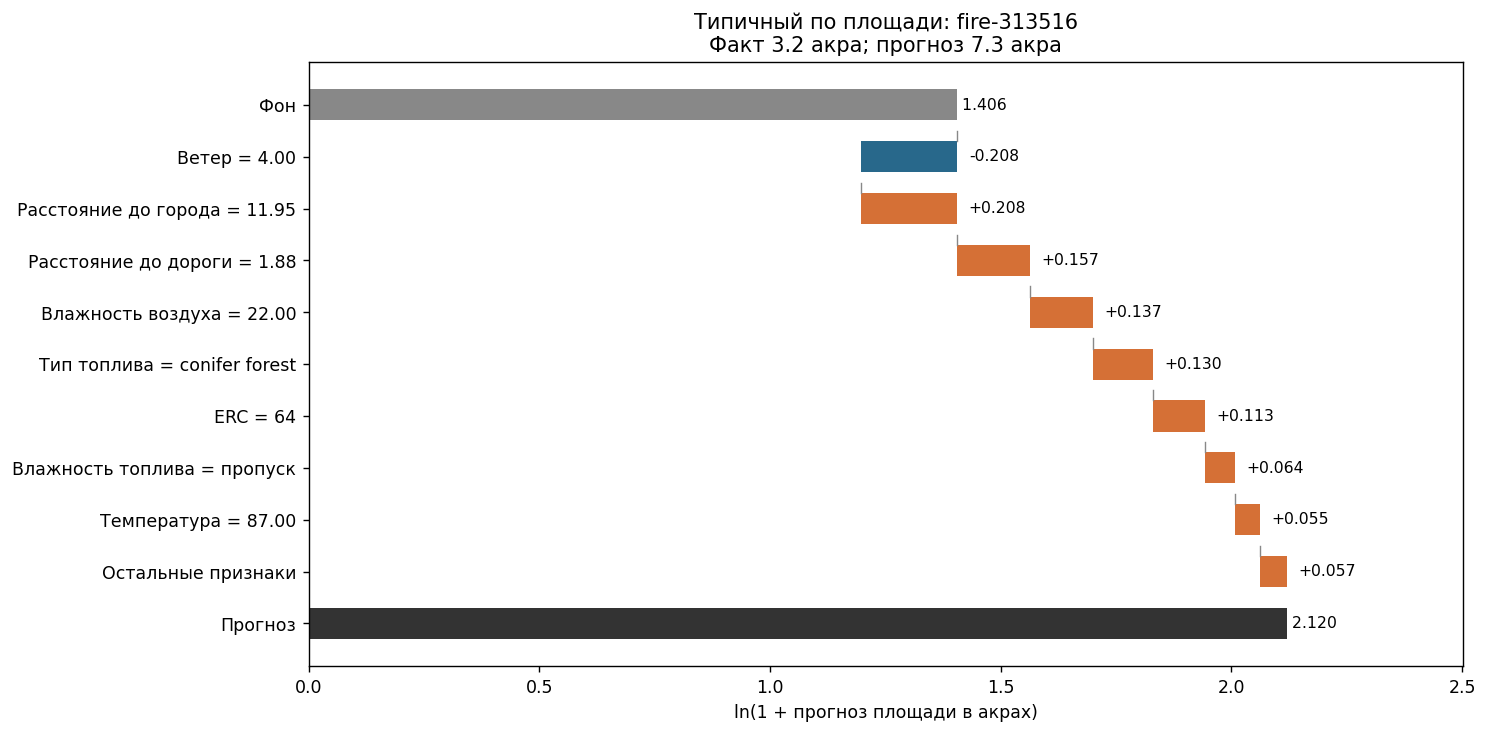

Случай: Типичный по площади


,feature,SHAP_log1p,MC_standard_error,observed_value
0,wind_speed_mph,-0.20839,0.00062,4.00
1,distance_to_town_mi,0.20772,0.00056,11.95
2,distance_to_road_mi,0.15710,0.00067,1.88
3,relative_humidity_pct,0.13734,0.00049,22.00
4,fuel_model,0.13016,0.00037,conifer forest
5,energy_release_component,0.11302,0.00055,64
6,fuel_moisture_pct,0.06416,0.00034,пропуск
7,temperature_f,0.05547,0.00045,87.00
8,slope_deg,-0.02869,0.00038,9.80
9,state,0.02762,0.00041,montana


Повышают прогноз относительно фона: Расстояние до города (+0.208), Расстояние до дороги (+0.157), Влажность воздуха (+0.137)
Снижают прогноз относительно фона: Ветер (-0.208), Уклон (-0.029)
Ошибка 4.13 акра. SHAP объясняет прогноз 7.33, а не фактическую итоговую площадь 3.20.


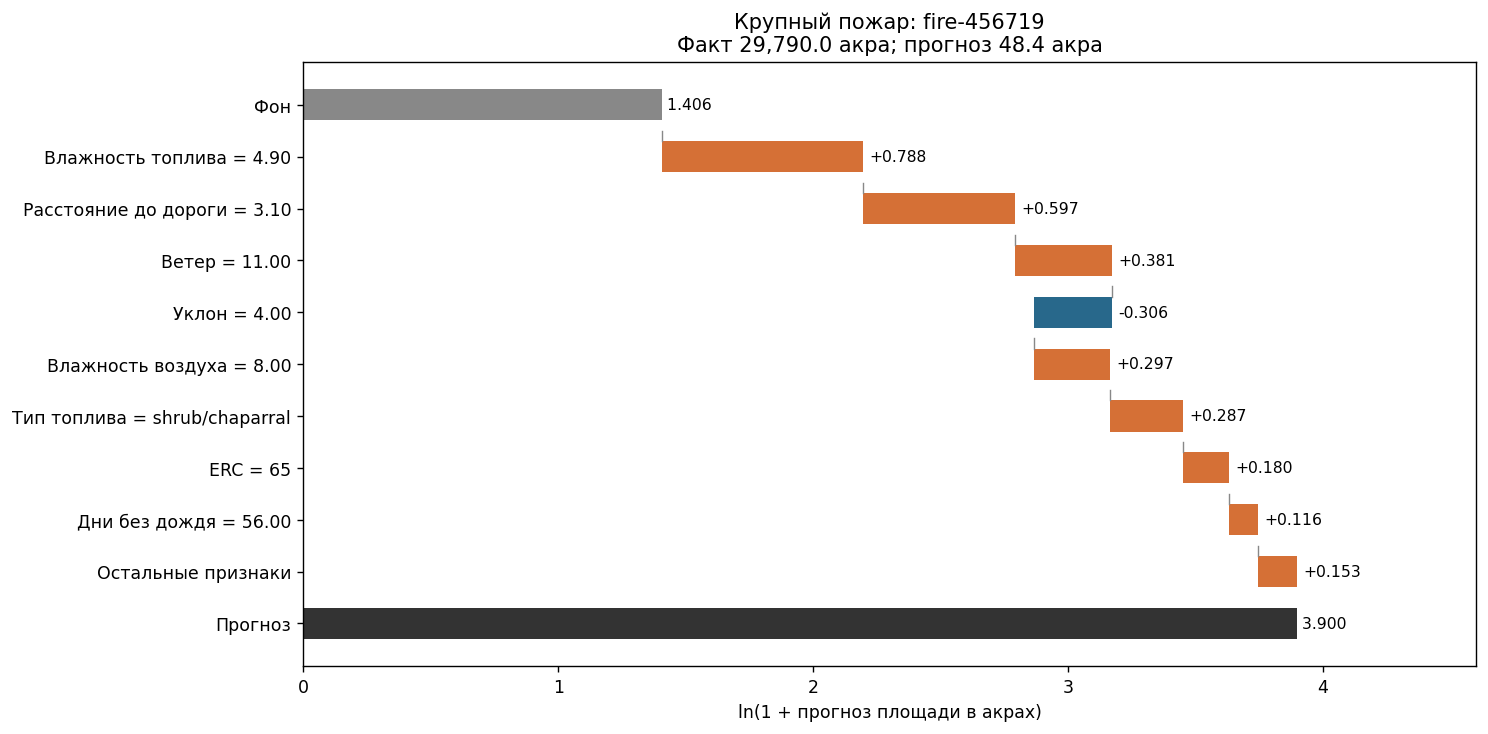

Случай: Крупный пожар


,feature,SHAP_log1p,MC_standard_error,observed_value
0,fuel_moisture_pct,0.78793,0.00455,4.90
1,distance_to_road_mi,0.59721,0.00362,3.10
2,wind_speed_mph,0.38114,0.00436,11.00
3,slope_deg,-0.30584,0.00247,4.00
4,relative_humidity_pct,0.29697,0.00223,8.00
5,fuel_model,0.28748,0.00307,shrub/chaparral
6,energy_release_component,0.18012,0.00241,65
7,days_since_rain,0.11574,0.00142,56.00
8,distance_to_town_mi,0.05699,0.00170,6.80
9,temperature_f,0.05102,0.00053,82.00


Повышают прогноз относительно фона: Влажность топлива (+0.788), Расстояние до дороги (+0.597), Ветер (+0.381)
Снижают прогноз относительно фона: Уклон (-0.306), Штат (-0.009)
Ошибка 29,741.61 акра. SHAP объясняет прогноз 48.39, а не фактическую итоговую площадь 29,790.00.


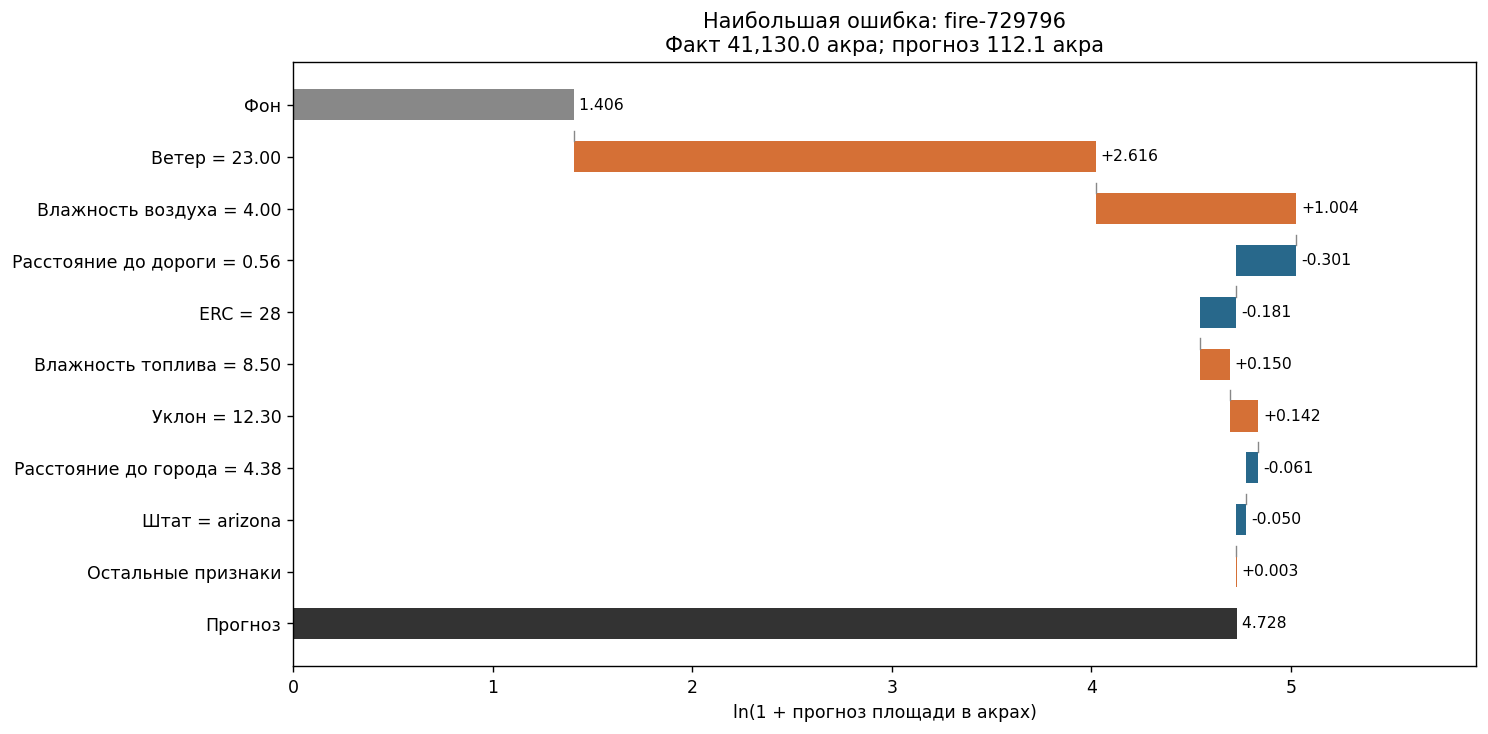

Случай: Наибольшая ошибка


,feature,SHAP_log1p,MC_standard_error,observed_value
0,wind_speed_mph,2.61554,0.00685,23.00
1,relative_humidity_pct,1.00401,0.00599,4.00
2,distance_to_road_mi,-0.30059,0.00443,0.56
3,energy_release_component,-0.18097,0.00239,28
4,fuel_moisture_pct,0.15017,0.00151,8.50
5,slope_deg,0.14182,0.00205,12.30
6,distance_to_town_mi,-0.06109,0.00321,4.38
7,state,-0.04979,0.00031,arizona
8,season_sin,-0.04393,0.00033,0.48
9,elevation_ft,0.03918,0.00086,4512


Повышают прогноз относительно фона: Ветер (+2.616), Влажность воздуха (+1.004), Влажность топлива (+0.150)
Снижают прогноз относительно фона: Расстояние до дороги (-0.301), ERC (-0.181), Расстояние до города (-0.061)
Ошибка 41,017.90 акра. SHAP объясняет прогноз 112.10, а не фактическую итоговую площадь 41,130.00.


In [34]:
def format_case_value(value):
    if isinstance(value,(float,np.floating)):
        return 'пропуск' if np.isnan(value) else f'{value:.2f}'
    return str(value)

def shap_waterfall(name,index,result,max_features=8):
    order = np.argsort(abs(result['phi']))[::-1]
    top = order[:max_features]
    contributions = [(result['features'][j],result['phi'][j]) for j in top]
    if len(order)>max_features:
        contributions.append(('Остальные признаки',float(result['phi'][order[max_features:]].sum())))
    base,final = result['base_value'],result['prediction']
    fig,ax = plt.subplots(figsize=(12,6))
    labels = ['Фон']
    ax.barh(0,base,color='#888888',height=.6)
    ax.text(base,0,f' {base:.3f}',va='center',fontsize=9)
    current = base
    for position,(feature,value) in enumerate(contributions,1):
        next_value = current+value
        color = '#d57036' if value>=0 else '#28688b'
        ax.barh(position,abs(value),left=min(current,next_value),color=color,height=.6)
        ax.plot([current,current],[position-.5,position-.3],color='#888888',linewidth=.8)
        label = feature if feature=='Остальные признаки' else (
            feature_names_ru[feature]+' = '+format_case_value(X.loc[index,feature]))
        labels.append(label)
        ax.text(max(current,next_value)+.025,position,f'{value:+.3f}',va='center',fontsize=9)
        current = next_value
    last = len(contributions)+1
    labels.append('Прогноз')
    ax.barh(last,final,color='#333333',height=.6)
    ax.text(final,last,f' {final:.3f}',va='center',fontsize=9)
    ax.set_yticks(range(len(labels)),labels=labels)
    ax.invert_yaxis()
    ax.set_xlabel('ln(1 + прогноз площади в акрах)')
    fact,forecast = case_summary.loc[name,[TARGET,'predicted_acres']]
    ax.set_title(f'{name}: {df.loc[index,"fire_id"]}\nФакт {fact:,.1f} акра; прогноз {forecast:,.1f} акра')
    ax.margins(x=.18)
    fig.tight_layout()
    plt.show()

shap_tables = {}
for name,index in case_indices.items():
    result = shap_results[name]
    table = pd.DataFrame({'feature':result['features'],'SHAP_log1p':result['phi'],
        'MC_standard_error':result['standard_error'],
        'observed_value':[format_case_value(X.loc[index,c]) for c in result['features']]})
    table = table.sort_values('SHAP_log1p',key=lambda col:col.abs(),ascending=False).reset_index(drop=True)
    shap_tables[name] = table
    shap_waterfall(name,index,result)
    print('Случай:',name)
    display(table.round(5))
    higher = table.loc[table.SHAP_log1p>0].nlargest(3,'SHAP_log1p')
    lower = table.loc[table.SHAP_log1p<0].nsmallest(3,'SHAP_log1p')
    print('Повышают прогноз относительно фона:',
          ', '.join(f'{feature_names_ru[r.feature]} ({r.SHAP_log1p:+.3f})' for r in higher.itertuples()))
    print('Снижают прогноз относительно фона:',
          ', '.join(f'{feature_names_ru[r.feature]} ({r.SHAP_log1p:+.3f})' for r in lower.itertuples()))
    fact,forecast = case_summary.loc[name,[TARGET,'predicted_acres']]
    print(f'Ошибка {abs(forecast-fact):,.2f} акра. SHAP объясняет прогноз {forecast:,.2f}, '
          f'а не фактическую итоговую площадь {fact:,.2f}.')


### Как читать случаи
Старт waterfall — средний log-прогноз на фоне. Оранжевые вклады увеличивают прогноз,
синие уменьшают; конечная сумма совпадает с применяемым прогнозом. «Остальные» — сумма
оставшихся вкладов, а не отброшенная часть объяснения.

У обычного события SHAP показывает баланс условий, из-за которого прогноз близок к нескольким
акрам. Для крупного пожара и максимального промаха важно сравнить **объяснимость решения**
с **правильностью решения**: хорошее разложение не исправляет сильную недооценку.
Модель могла верно отреагировать на ветер и удалённость, но не предвидеть масштаб редкого
развития. Для заключения о реальной причине промаха нужны сведения о будущем ветре,
времени фактического начала, доступности сил, ходе тушения и состоянии топливного разрыва.
Из SHAP нельзя вывести, какое из этих ненаблюдаемых обстоятельств действительно произошло.

### Что произошло в трёх выбранных случаях
**Типичный по площади, fire-313516:** факт 3,2 акра, прогноз 7,33. Ветер 4 мили/ч
снижает log-прогноз на 0,208, удалённость города 11,95 мили повышает почти на столько же.
Влажность воздуха 22%, conifer forest и ERC 64 добавляют положительные вклады.
Прогноз остаётся в пределах нескольких акров, но площадь переоценена примерно в 2,3 раза.
Пропущенная влажность топлива также участвует в объяснении через обработку пропусков;
сам пропуск не является физической причиной увеличения площади.

**Крупный пожар, fire-456719:** факт 29 790 акров, прогноз 48,39. Влажность топлива
4,9% (SHAP +0,788), удаление от дороги 3,10 мили (+0,597) и ветер 11 миль/ч (+0,381)
поднимают прогноз; уклон 4° снижает его (−0,306). Модель распознала неблагоприятные
условия относительно фона, но недооценила итоговую площадь примерно в 616 раз.

**Максимальная ошибка, fire-729796:** факт 41 130 акров, прогноз 112,10. Ветер 23 мили/ч
даёт самый сильный положительный вклад (+2,616), влажность воздуха 4% добавляет +1,004.
Близость дороги 0,56 мили (−0,301) и ERC 28 (−0,181) уменьшают прогноз.
Даже очень сильный положительный вклад ветра не означает, что модель умеет предсказать
редкий пожар такого размера: недооценка примерно в 367 раз, ошибка 41 017,90 акра.
Причину несоответствия этим SHAP-разложением установить нельзя.


## 10. Итоговое заключение для диспетчерской службы
**Назначение:** оценка итоговой площади по погоде, топливу, географии и календарной
сезонности на момент сообщения. Причина после расследования, точная ретроспективная
задержка и число отправленных расчётов в модель не входят.

Следующая ячейка объединяет фактические результаты всех разделов. Цены недооценки и
переоценки и ограничение числа расчётов не заданы, поэтому правила отправки сил
или денежную экономию по этому заданию не вычисляем.


In [44]:
selected_report = quality_time.loc[expanded_best_name]
report_tail = expanded_tail.loc[expanded_best_name]
print('Итог для диспетчерской службы')
print('Что прогнозируем. Итоговую площадь при исторической практике тушения, а не площадь без вмешательства.')
print('На что опираемся. Основные факторы: расстояние до дороги и ветер; далее ERC, уклон, '
      'удалённость города и тип топлива. Корреляция и важность не доказывают причинное влияние.')
print('   PDP ветра показывает ступенчатый рост с усилением на больших скоростях; '
      'PDP расстояния до дороги в целом растёт, но имеет локальный немонотонный участок. '
      'Форма и уровень различаются по топливу. Пороги деревьев не являются нормативами отправки сил.')
print(f'Точность. {expanded_best_name}: RMSLE={selected_report.RMSLE:.3f}, '
      f'MAE={selected_report.MAE_acres:.2f} акра, RMSE={selected_report.RMSE_acres:.2f} акра; '
      f'R² в акрах={selected_report.R2_acres:.3f}. Это историческая проверка 2024 после настройки по 2023.')
print(f'Где ошибаемся. Среднее смещение {selected_report.bias_acres:.2f} акра; '
      f'у {selected_report.under_by_2x_pct:.1f}% всех событий прогноз меньше половины факта. '
      f'Среди {int(report_tail.n_large)} пожаров от 1000 акров таких {report_tail.large_under_by_2x_pct:.1f}%.')
worst = case_summary.loc['Наибольшая ошибка']
print(f'   Максимальный промах: {worst.fire_id}, факт {worst[TARGET]:,.1f} акра, '
      f'прогноз {worst.predicted_acres:,.1f} акра, ошибка {worst.absolute_error_acres:,.1f} акра.')
print('   Хороший RMSLE и объяснение SHAP не означают надёжного прогноза редких крупнейших пожаров.')
print(f'Изменение процесса. Перелом задержки обнаружения — {delay_break_year}; '
      'после него ошибки возле дорог и вдали меняются в противоположных направлениях. '
      'Поэтому нужно проверять топливо, территории и удалённость отдельно.')
print('Переобучение. Рабочая схема — ежегодно до начала апрельского сезона на накопленных '
      'завершённых событиях; предварительно выбираем расширяющееся окно по временным фолдам. '
      'Оптимальная частота обновления шестью сезонами не установлена.')
print('   С апреля по октябрь — ежемесячная проверка пропусков, категорий, входных распределений '
      'и ошибок по зрелым когортам с известным исходом. Не сравнивать только быстро потушенные события.')
print('   При устойчивом ухудшении ошибок или изменении мониторинга, карт топлива, '
      'топливных разрывов и практики тушения — досрочная временная проверка и обновление модели.')
print('Решение о силах. Точечный прогноз не задаёт безопасную верхнюю границу. '
      'Для выбора одного или нескольких расчётов ещё нужны цена ошибок, доступность сил '
      'и отдельная оценка риска крупного пожара/верхних квантилей площади.')
print('Следующая независимая проверка. Новый завершённый сезон: 2024 уже использован '
      'для исторических сравнений и объяснений. После обновления параметры проверяются на будущем целом сезоне.')

Итог для диспетчерской службы
Что прогнозируем. Итоговую площадь при исторической практике тушения, а не площадь без вмешательства.
На что опираемся. Основные факторы: расстояние до дороги и ветер; далее ERC, уклон, удалённость города и тип топлива. Корреляция и важность не доказывают причинное влияние.
   PDP ветра показывает ступенчатый рост с усилением на больших скоростях; PDP расстояния до дороги в целом растёт, но имеет локальный немонотонный участок. Форма и уровень различаются по топливу. Пороги деревьев не являются нормативами отправки сил.
Точность. Градиентный бустинг: RMSLE=0.849, MAE=73.93 акра, RMSE=1272.52 акра; R² в акрах=0.006. Это историческая проверка 2024 после настройки по 2023.
Где ошибаемся. Среднее смещение -66.22 акра; у 22.0% всех событий прогноз меньше половины факта. Среди 13 пожаров от 1000 акров таких 100.0%.
   Максимальный промах: fire-729796, факт 41,130.0 акра, прогноз 112.1 акра, ошибка 41,017.9 акра.
   Хороший RMSLE и объяснение SHAP не означают над